# ¿Cuánto gas necesitará España este invierno?

**Práctica transversal 1 · Análisis Avanzado de Series Temporales · GRDAN 2627 · ESIC University**
Autor: Carlos Jurado · Octubre de 2026

---

**Encargo.** La Secretaría de Estado de Energía (MITECO) necesita saber cuánto gas natural consumirá España entre **octubre de 2026 y marzo de 2027**, mes a mes, para dimensionar el aprovisionamiento (almacenamiento y cargamentos de GNL) y decidir si prepara medidas de reducción de demanda. El contexto es de tensión: Ormuz prácticamente cerrado desde febrero, almacenamientos de la UE al 71 % (España al 73 %) y un TTF en torno a 80 €/MWh.

**Datos.** Demanda diaria de gas natural en España (CNMC, con datos de Enagás GTS), de enero de 2009 a marzo de 2026, separada en **demanda convencional** y **sector eléctrico**. La ficha de la fuente está en el [`README.md`](README.md) de esta carpeta.

## Resumen ejecutivo

| | |
|---|---|
| **Predicción del invierno 2026/27** | **≈ 188 TWh** de octubre a marzo (seasonal naïve sobre la demanda total), con un pico en **enero (≈ 36 TWh)** y **diciembre (≈ 35 TWh)**. Es la misma cifra que el invierno 2025/26 y un 1 % más que la media de los cinco últimos inviernos. |
| **Rango razonable** | Corrigiendo con el sesgo observado entre abril y septiembre de 2026, el rango va de **184 a 193 TWh**. Un invierno frío o con poca hidráulica y eólica empujaría hacia la parte alta. |
| **Componentes** | La demanda convencional (≈ 70 % del total) es estacional y muy predecible; el seasonal naïve falla menos de un 5 % al mes. El **sector eléctrico es la gran fuente de incertidumbre**: entre julio y septiembre de 2026 crece más de un 30 % interanual y ningún método de referencia lo anticipa. |
| **Contraste con Enagás** | De abril a agosto de 2026 el modelo de la demanda total se desvía solo un **−1,8 %** del avance de Enagás, y los cinco meses caen dentro de la banda del 80 %. |
| **Recomendación** | Asegurar suministro para **~190 TWh**, con el refuerzo de GNL concentrado en **diciembre y enero**. Preparar, sin activar todavía, un plan de reducción de demanda con disparadores objetivos. Vigilar de forma mensual el gas para generación eléctrica. |

## Índice
- [0 · Entorno](#0)
- [A · Preparar los datos](#A)
- [B · Ver la serie en diario](#B)
- [C · Descomponer](#C)
- [D · Fijar el listón](#D)
- [E · Diagnosticar](#E)
- [F · Predecir el invierno y recomendar](#F)

<a id="0"></a>
## 0 · Entorno

Todo el código de modelización usa la suite de **Nixtla** (`statsforecast`, `utilsforecast`, `coreforecast`) con los datos en formato largo (`unique_id`, `ds`, `y`). `statsmodels` se usa solo para gráficos y contrastes clásicos (ACF, Ljung-Box, descomposición clásica y STL). Las versiones exactas están en [`requirements.txt`](../requirements.txt).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, SeasonalNaive, RandomWalkWithDrift, MSTL
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse, mape
from coreforecast.scalers import boxcox_lambda, boxcox
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "legend.frameon": False,
})

# Paleta fija por serie para que cada componente se reconozca en todo el notebook
COLORS = {"Total": "#1f3b73", "Convencional": "#2a9d8f", "Sector eléctrico": "#e76f51"}
SERIES = list(COLORS)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
def mes(d):
    """Fecha -> 'oct-2026' (etiqueta de mes en español, independiente del locale del sistema)."""
    return f"{MESES[d.month - 1]}-{d.year}"

<a id="A"></a>
## A · Preparar los datos

### A.1 · Descarga desde el código

El CSV **no se versiona** (`data/` está en `.gitignore`). Se descarga en cada ejecución desde el catálogo de datos abiertos de la CNMC; la primera vez queda guardado en `data/` como caché.

In [2]:
# Localizamos el recurso CSV a través de la API CKAN del catálogo de la CNMC,
# en vez de fijar la URL a mano: si la CNMC republica el fichero, el código sigue funcionando.
CKAN_API = "https://catalogodatos.cnmc.es/api/3/action/package_show"
DATASET_ID = "ds_24333_1"   # «Evolución diaria de la demanda de gas en España»
RAW_PATH = DATA_DIR / "cnmc_demanda_gas_diaria.csv"
REFRESH = False             # True para forzar una descarga nueva

meta = requests.get(CKAN_API, params={"id": DATASET_ID}, timeout=60).json()["result"]
csv_url = next(r["url"] for r in meta["resources"] if r["format"] == "CSV" and r["url"].endswith(".csv"))

if REFRESH or not RAW_PATH.exists():
    resp = requests.get(csv_url, timeout=120)
    resp.raise_for_status()
    RAW_PATH.write_bytes(resp.content)

print(f"Conjunto      : {meta['title']}")
print(f"Publica       : {meta['author']}  |  Fuente: Enagás GTS")
print(f"Licencia      : {meta['license_title']}")
print(f"Actualización : {next(e['value'] for e in meta['extras'] if e['key'] == 'frecuenciaActualizacion')}"
      f"  |  última modificación del catálogo: {meta['metadata_modified'][:10]}")
print(f"Fichero local : {RAW_PATH}  ({RAW_PATH.stat().st_size / 1e6:.1f} MB)")

Conjunto      : Evolución diaria de la demanda de gas en España
Publica       : CNMC  |  Fuente: Enagás GTS
Licencia      : Creative Commons Attribution Share-Alike 4.0
Actualización : Trimestral  |  última modificación del catálogo: 2026-09-01
Fichero local : data\cnmc_demanda_gas_diaria.csv  (1.1 MB)


### A.2 · Carga

El fichero está en formato largo: una fila por día y tipo de demanda, con la cantidad en **MWh**. Hay tres tipos: gasoducto y cisternas de GNL (que juntas forman la demanda convencional) y el sector eléctrico.

In [3]:
raw = pd.read_csv(RAW_PATH, sep=";", encoding="utf-8-sig")
raw.columns = ["ds", "tipo", "mwh"]
raw["ds"] = pd.to_datetime(raw["ds"], format="%Y-%m-%d")
print(raw.dtypes, "\n")
print(raw["tipo"].value_counts())
raw.head()

ds      datetime64[ns]
tipo            object
mwh              int64
dtype: object 

tipo
Demanda convencional - demanda por gasoducto       6299
Demanda convencional - demanda GNL en cisternas    6299
demanda sector eléctrico                           6299
Name: count, dtype: int64


,ds,tipo,mwh
0,2009-01-01,Demanda convencional - demanda por gasoducto,503200
1,2009-01-01,Demanda convencional - demanda GNL en cisternas,3910
2,2009-01-01,demanda sector eléctrico,151450
3,2009-01-02,Demanda convencional - demanda por gasoducto,590630
4,2009-01-02,Demanda convencional - demanda GNL en cisternas,39200


### A.3 · Controles de calidad: huecos, duplicados y valores imposibles

In [4]:
# 1) Cobertura y huecos: ¿hay algún día del calendario sin dato?
calendar = pd.date_range(raw["ds"].min(), raw["ds"].max(), freq="D")
missing_days = calendar.difference(raw["ds"].unique())

# 2) Duplicados: un registro por día y componente
dups = raw.duplicated(["ds", "tipo"]).sum()

# 3) Completitud: cada día debe tener las 3 componentes
per_day = raw.groupby("ds")["tipo"].nunique()

# 4) Valores imposibles
non_positive = (raw["mwh"] <= 0).sum()

quality = pd.Series({
    "Primer día": raw["ds"].min().date(),
    "Último día": raw["ds"].max().date(),
    "Días de calendario": len(calendar),
    "Días sin dato": len(missing_days),
    "Registros duplicados (día, componente)": dups,
    "Días con < 3 componentes": (per_day < 3).sum(),
    "Valores ≤ 0": non_positive,
    "Nulos": raw["mwh"].isna().sum(),
}, name="Control")
quality.to_frame()

,Control
Primer día,2009-01-01
Último día,2026-03-31
Días de calendario,6299
Días sin dato,0
"Registros duplicados (día, componente)",0
Días con < 3 componentes,0
Valores ≤ 0,0
Nulos,0


**Lectura.** La serie está **completa**: los 6.299 días entre el 1-ene-2009 y el 31-mar-2026 tienen sus tres componentes, sin duplicados, sin nulos y sin valores negativos ni cero. No hace falta imputar nada. El último dato es de **marzo de 2026**: la CNMC actualiza **trimestralmente** y va unos 6 meses por detrás, lo que obliga a contrastar la predicción con los avances de Enagás (bloque F).

### A.4 · Unidades, total y componentes

- **Convencional** = gasoducto + cisternas de GNL (hogares, comercios, pymes e industria).
- **Sector eléctrico** = gas entregado a los ciclos combinados para producir electricidad.
- **Total** = convencional + sector eléctrico.

Para trabajar con números legibles pasamos de MWh/día a **GWh/día** (y más adelante a TWh/mes).

In [5]:
# Pasamos a ancho (una columna por componente) para construir los agregados
COMP_MAP = {
    "Demanda convencional - demanda por gasoducto": "Gasoducto",
    "Demanda convencional - demanda GNL en cisternas": "Cisternas GNL",
}
raw["comp"] = raw["tipo"].map(COMP_MAP).fillna("Sector eléctrico")
wide = raw.pivot(index="ds", columns="comp", values="mwh").asfreq("D")

daily = pd.DataFrame(index=wide.index)
daily["Convencional"] = wide["Gasoducto"] + wide["Cisternas GNL"]
daily["Sector eléctrico"] = wide["Sector eléctrico"]
daily["Total"] = daily["Convencional"] + daily["Sector eléctrico"]
daily = daily[SERIES] / 1_000          # MWh -> GWh/día

# Control de unidades: la suma anual de 2025 debe cuadrar con los 331 TWh publicados por Enagás
annual_twh = daily.groupby(daily.index.year).sum() / 1_000
print(f"Total 2025 según CNMC: {annual_twh.loc[2025, 'Total']:.1f} TWh  (Enagás: 331 TWh)  -> la unidad es MWh/día")
print(f"Rango diario total: {daily['Total'].min():,.0f} – {daily['Total'].max():,.0f} GWh/día")

# Formato largo de Nixtla: unique_id, ds, y
Y_daily = (daily.reset_index().melt(id_vars="ds", var_name="unique_id", value_name="y")
           [["unique_id", "ds", "y"]].sort_values(["unique_id", "ds"], ignore_index=True))
Y_daily.head()

Total 2025 según CNMC: 331.4 TWh  (Enagás: 331 TWh)  -> la unidad es MWh/día
Rango diario total: 515 – 1,886 GWh/día


,unique_id,ds,y
0,Convencional,2009-01-01,507.11
1,Convencional,2009-01-02,629.83
2,Convencional,2009-01-03,624.13
3,Convencional,2009-01-04,631.88
4,Convencional,2009-01-05,776.23


**Control de unidades.** La suma de 2025 da **331,4 TWh**, la misma cifra que publica Enagás (331 TWh). Eso confirma que la columna está en MWh/día y que el total que hemos construido es el correcto.

### A.5 · ¿Hay valores atípicos?

Marcamos los días que se alejan más de 6 desviaciones robustas (MAD) de su mediana móvil de 15 días.

In [6]:
# Detección de atípicos: residuo frente a la mediana móvil de 15 días, en unidades de MAD
def flag_outliers(s, window=15, k=6):
    med = s.rolling(window, center=True, min_periods=1).median()
    dev = s - med
    mad = dev.abs().rolling(91, center=True, min_periods=1).median()
    return (dev.abs() / (1.4826 * mad)) > k

outliers = pd.DataFrame({c: flag_outliers(daily[c]) for c in SERIES})
print("Días marcados como atípicos (|z robusto| > 6):")
print(outliers.sum().to_string())

# ¿Qué días son? Se concentran en festivos (Navidad, Año Nuevo, Semana Santa, puentes)
flag = daily.loc[outliers["Convencional"], ["Convencional"]]
flag["mediana 15 d"] = daily["Convencional"].rolling(15, center=True, min_periods=1).median()[flag.index]
flag["día"] = flag.index.strftime("%d-%m")
print("\nDías atípicos más frecuentes en Convencional (día-mes):")
print(flag["día"].value_counts().head(8).to_string())
flag.round(0).sort_values("Convencional").head(8)

Días marcados como atípicos (|z robusto| > 6):
Total                0
Convencional        49
Sector eléctrico     2

Días atípicos más frecuentes en Convencional (día-mes):
día
15-07    3
24-06    2
01-07    2
02-07    2
08-07    2
17-06    2
12-07    2
27-06    1


,Convencional,mediana 15 d,día
ds,,,
2009-07-12,419.00,580.00,12-07
2023-07-02,419.00,550.00,02-07
2023-07-15,420.00,544.00,15-07
2023-07-01,428.00,550.00,01-07
2015-07-05,450.00,583.00,05-07
2010-07-25,453.00,625.00,25-07
2010-07-18,456.00,639.00,18-07
2010-07-11,461.00,651.00,11-07


**Lectura.** En la demanda total no aparece ningún atípico. Los 49 días marcados en la convencional son **fines de semana y festivos de verano** (junio-julio), cuando la demanda es mínima y el consumo industrial cae de golpe. **Son demanda real**, no errores de medida, así que se mantienen: forman parte del patrón semanal que veremos en el bloque B.

### A.6 · ¿Cuánto pesa cada componente?

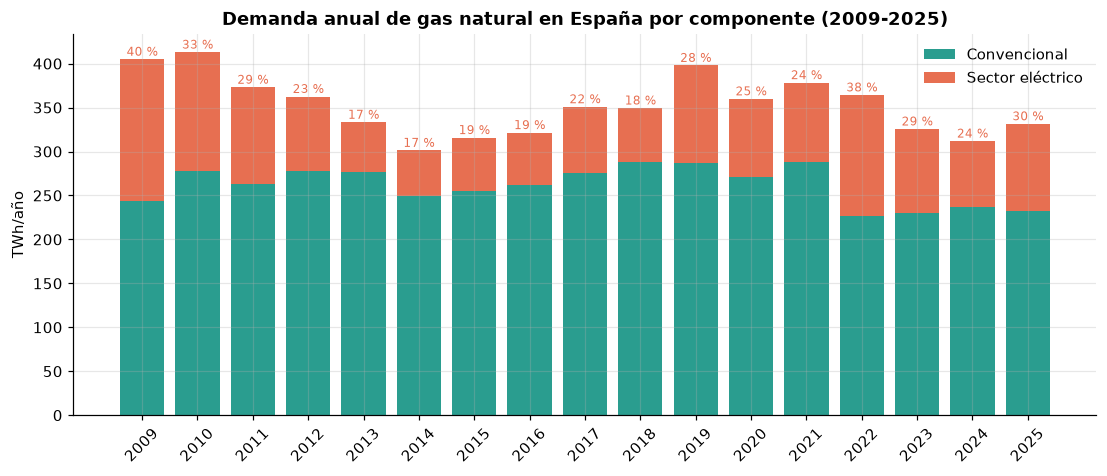

,Media 2009-2025 (%),Mínimo (%),Año mín.,Máximo (%),Año máx.,2025 (%)
Convencional,74.43,60.07,2009,82.92,2013,69.92
Sector eléctrico,25.57,17.08,2013,39.93,2009,30.08


In [7]:
share = annual_twh[["Convencional", "Sector eléctrico"]].div(annual_twh["Total"], axis=0) * 100
weights = pd.concat({"TWh": annual_twh.round(1), "% del total": share.round(1)}, axis=1)
weights = weights[weights.index <= 2025]   # 2026 es un año incompleto (ene-mar)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(annual_twh.index[:-1], annual_twh["Convencional"].iloc[:-1], color=COLORS["Convencional"], label="Convencional")
ax.bar(annual_twh.index[:-1], annual_twh["Sector eléctrico"].iloc[:-1], bottom=annual_twh["Convencional"].iloc[:-1],
       color=COLORS["Sector eléctrico"], label="Sector eléctrico")
for yr, row in annual_twh.iloc[:-1].iterrows():
    ax.text(yr, row["Total"] + 4, f"{share.loc[yr, 'Sector eléctrico']:.0f} %", ha="center", fontsize=8, color=COLORS["Sector eléctrico"])
ax.set(title="Demanda anual de gas natural en España por componente (2009-2025)", ylabel="TWh/año", xlabel="")
ax.set_xticks(annual_twh.index[:-1])
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper right")
plt.show()

summary = pd.DataFrame({
    "Media 2009-2025 (%)": share.loc[:2025].mean(),
    "Mínimo (%)": share.loc[:2025].min(),
    "Año mín.": share.loc[:2025].idxmin(),
    "Máximo (%)": share.loc[:2025].max(),
    "Año máx.": share.loc[:2025].idxmax(),
    "2025 (%)": share.loc[2025],
})
summary

**Lectura de negocio.**
- La **demanda convencional es el grueso**: un 74 % de media entre 2009 y 2025, y un 70 % en 2025. Es la parte que depende del frío y de la actividad industrial.
- El **sector eléctrico pesa entre el 17 % (2013) y el 40 % (2009)** y es el componente que más oscila. Su peso depende de cuánta electricidad no cubren las renovables, la hidráulica y la nuclear: en años secos o con poco viento los ciclos combinados entran más.
- En 2025 el gas para generar electricidad sube un 33 % y vuelve a pesar un 30 %. Tras el apagón del 28 de abril de 2025, REE opera el sistema en "modo reforzado", con más ciclos combinados acoplados. **Para el aprovisionamiento eso significa que una de cada tres moléculas que hay que asegurar depende de la meteorología del sistema eléctrico, no del frío.**

<a id="B"></a>
## B · Ver la serie en diario

### B.1 · Gráfico temporal y medias móviles

Sobre cada serie diaria dibujamos la media móvil de 7 días, que elimina el patrón semanal, y la de 365 días, que elimina el anual y deja ver la tendencia.

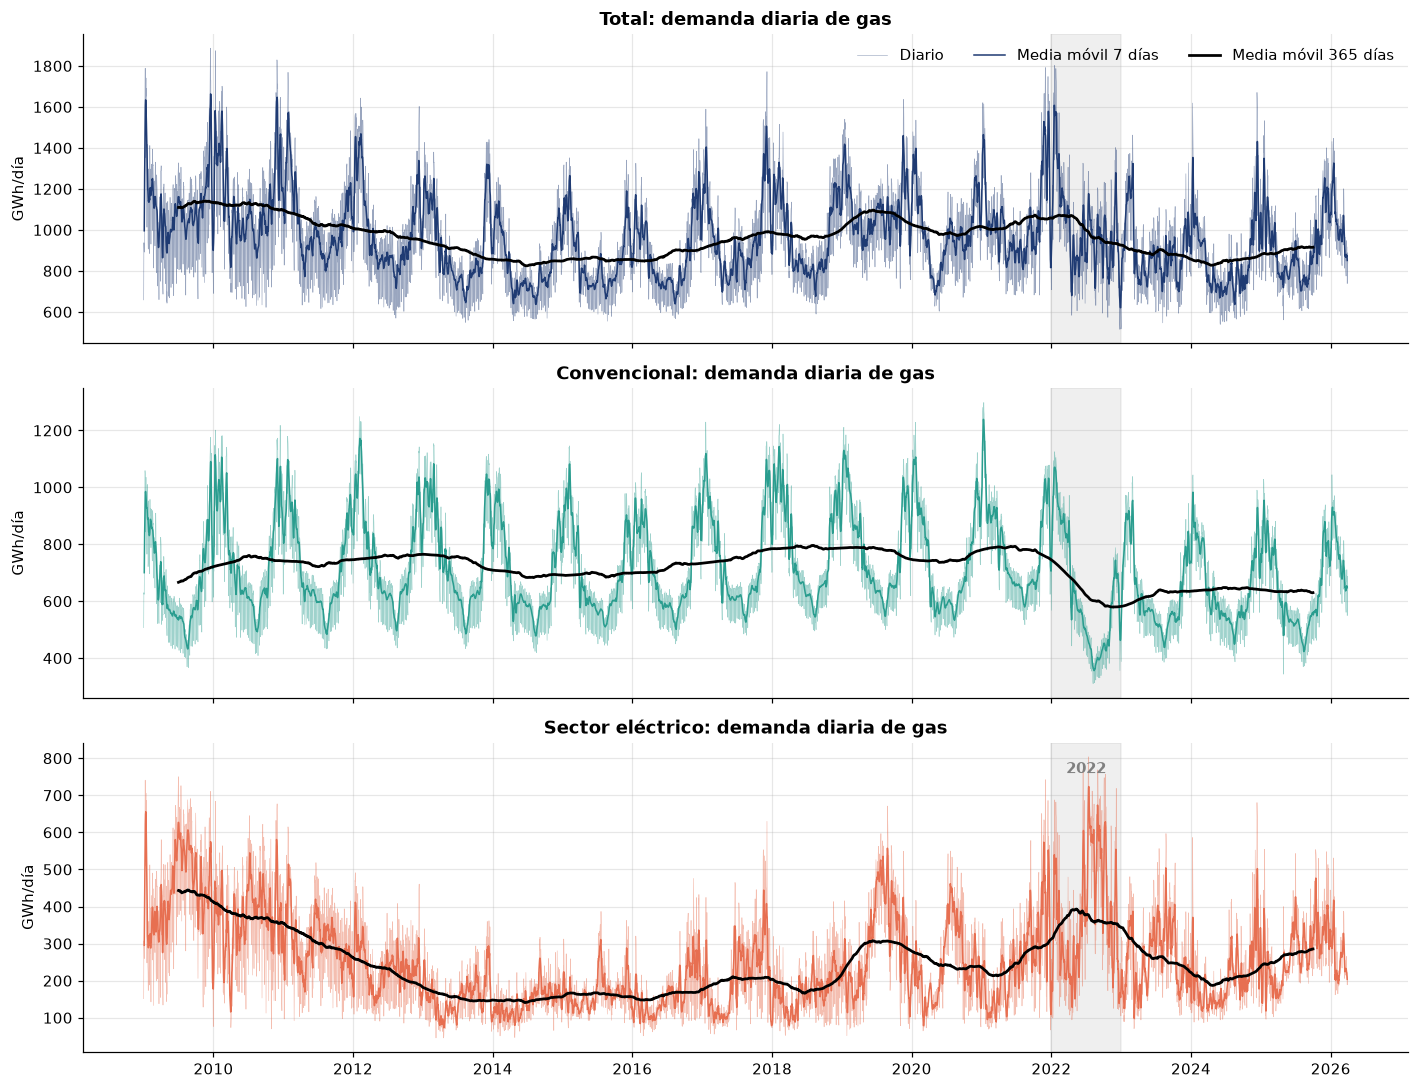

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(daily.index, daily[s], color=COLORS[s], lw=0.4, alpha=0.45, label="Diario")
    ax.plot(daily.index, daily[s].rolling(7, center=True).mean(), color=COLORS[s], lw=1.0, label="Media móvil 7 días")
    ax.plot(daily.index, daily[s].rolling(365, center=True).mean(), color="black", lw=1.8, label="Media móvil 365 días")
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="grey", alpha=0.12)
    ax.set(title=f"{s}: demanda diaria de gas", ylabel="GWh/día")
axes[0].legend(loc="upper right", ncol=3)
axes[-1].annotate("2022", xy=(pd.Timestamp("2022-07-01"), 760), ha="center", color="grey", fontweight="bold")
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

**Lectura.**
- **Convencional:** estacionalidad anual muy marcada y regular, con picos de 1.000-1.200 GWh/día en invierno y valles de 400-500 GWh/día en agosto. El nivel de fondo se mantiene estable en torno a 700-790 GWh/día hasta 2021, **se desploma en 2022** (hasta ~580) y desde entonces se queda en un escalón más bajo, alrededor de 630 GWh/día. No ha vuelto al nivel previo a la crisis.
- **Sector eléctrico:** mucho más ruidoso y sin un patrón anual nítido. La tendencia baja de ~440 GWh/día en 2009 a ~150 en 2014-2016, cuando las renovables desplazaron al gas, y luego oscila por ciclos: 2019 (salida del carbón), **2022 (máximo)**, 2024 (mínimo) y 2025-26 (subida).
- **Total:** hereda la forma estacional de la convencional y los vaivenes del eléctrico. Por eso su tendencia es más irregular que la de cualquiera de sus componentes.

### B.2 · Gráficos estacionales: anual y semanal

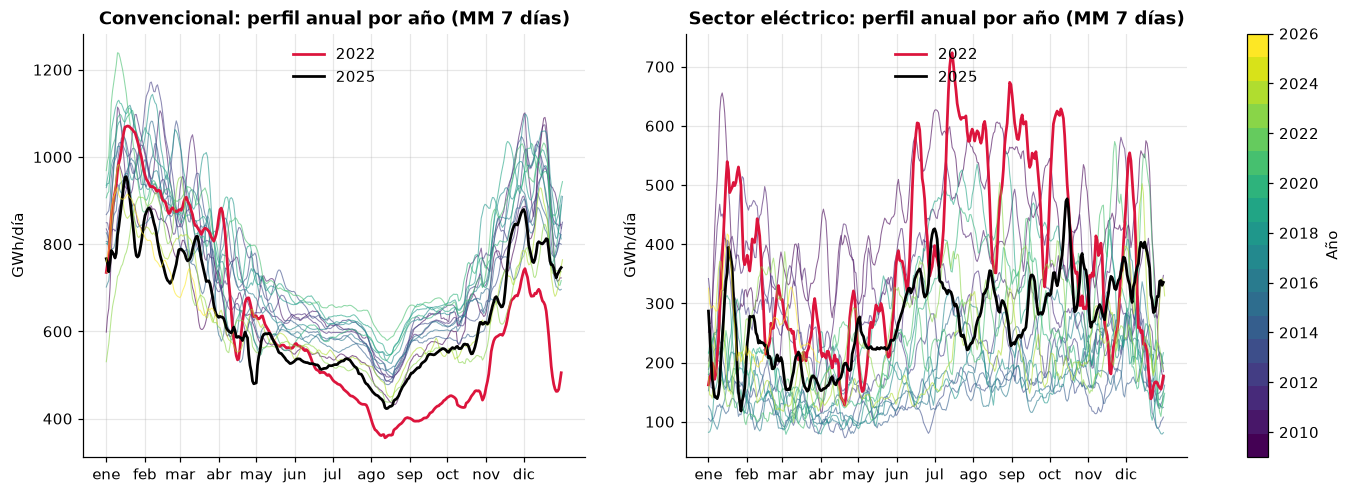

In [9]:
# Gráfico estacional anual: cada línea es un año, eje x = día del año (media móvil de 7 días para leer la forma)
smooth = daily.rolling(7, center=True, min_periods=4).mean()
smooth["year"], smooth["doy"] = smooth.index.year, smooth.index.dayofyear
years = sorted(smooth["year"].unique())
cmap = plt.get_cmap("viridis", len(years))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, s in zip(axes, ["Convencional", "Sector eléctrico"]):
    for i, yr in enumerate(years):
        d = smooth[smooth["year"] == yr]
        highlight = yr in (2022, 2025)
        ax.plot(d["doy"], d[s], color="crimson" if yr == 2022 else ("black" if yr == 2025 else cmap(i)),
                lw=1.8 if highlight else 0.7, alpha=1 if highlight else 0.6, label=str(yr) if highlight else None)
    ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
                  ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
    ax.set(title=f"{s}: perfil anual por año (MM 7 días)", ylabel="GWh/día")
    ax.legend(loc="upper center")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(min(years), max(years)))
fig.colorbar(sm, ax=axes, label="Año", fraction=0.025)
plt.show()

**Lectura del gráfico anual.**
- **Convencional:** todos los años siguen la misma "U": la demanda cae de enero a agosto y sube de septiembre a diciembre. **El invierno multiplica por 2 o 2,5 la demanda del verano.** 2022 (rojo) arranca normal y a partir de marzo se queda claramente por debajo de todos los años, con un hundimiento en otoño-invierno: es la reducción de demanda por precio. 2025 (negro) se sitúa en la parte baja del abanico.
- **Sector eléctrico:** no hay una forma estacional estable. Algunos años tienen picos en verano (más aire acondicionado y menos viento) y otros en invierno. 2022 está muy por encima del resto de mayo a octubre: sequía, menos nuclear en Francia y exportaciones de electricidad. Las curvas de los distintos años se cruzan sin orden: **lo que pasó el año anterior dice poco de lo que pasará este**.

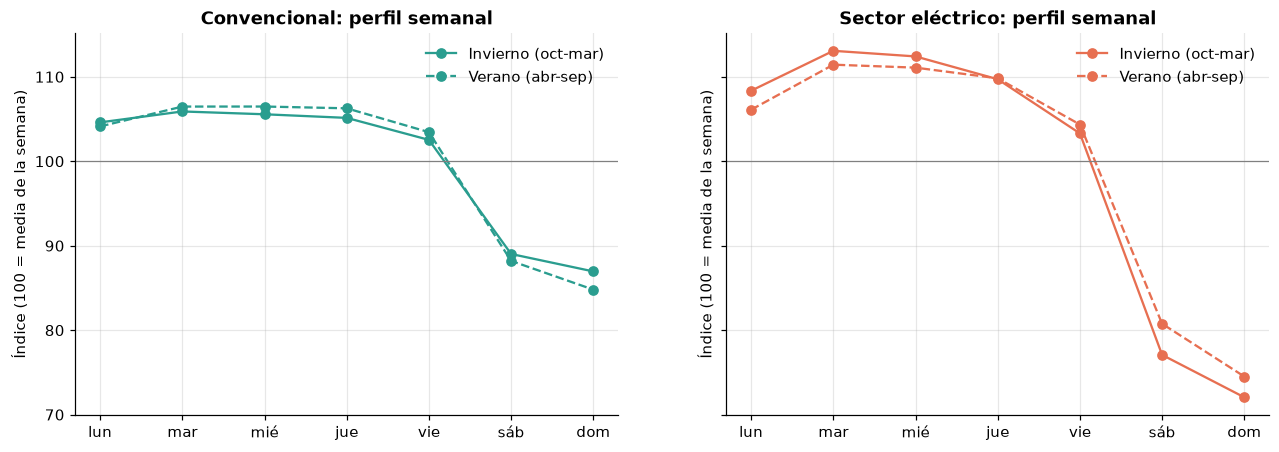

,lun,mar,mié,jue,vie,sáb,dom
Convencional,104.40,106.20,106.00,105.70,103.00,88.60,85.90
Sector eléctrico,107.20,112.30,111.80,109.80,103.80,78.90,73.30


In [10]:
# Gráfico estacional semanal: demanda de cada día relativa a la media de su semana (índice, 100 = media semanal)
DOW = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
week_idx = daily.copy()
for s in SERIES:
    week_idx[s] = 100 * daily[s] / daily[s].rolling(7, center=True).mean()
week_idx["dow"] = week_idx.index.dayofweek
week_idx["season"] = np.where(week_idx.index.month.isin([10, 11, 12, 1, 2, 3]), "Invierno (oct-mar)", "Verano (abr-sep)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, s in zip(axes, ["Convencional", "Sector eléctrico"]):
    prof = week_idx.groupby(["season", "dow"])[s].mean().unstack(0)
    for col, ls in zip(prof.columns, ["-", "--"]):
        ax.plot(DOW, prof[col], marker="o", ls=ls, color=COLORS[s], label=col)
    ax.axhline(100, color="grey", lw=0.8)
    ax.set(title=f"{s}: perfil semanal", ylabel="Índice (100 = media de la semana)")
    ax.legend()
plt.show()

week_idx.groupby("dow")[["Convencional", "Sector eléctrico"]].mean().set_axis(DOW).T.round(1)

**Lectura del gráfico semanal.** Las dos componentes bajan el fin de semana, pero con distinta intensidad:
- **Convencional:** de lunes a jueves está un 4-6 % por encima de la media semanal; el sábado (−11 %) y el domingo (−14 %) cae porque la industria para. En verano el valle del domingo es algo más profundo (85 frente a 87), porque casi todo el consumo es industrial.
- **Sector eléctrico:** el patrón es el doble de fuerte, con el martes un 12 % por encima y el domingo un **−27 %**. La demanda eléctrica del fin de semana es menor y la cubren las renovables y la nuclear, así que los ciclos combinados, que entran los últimos, son los primeros en salir.
- **Implicación operativa:** el día de máxima demanda que tiene que cubrir el sistema gasista es **un día laborable de enero o diciembre con frío**, nunca un fin de semana.

### B.3 · Diagramas de retardos

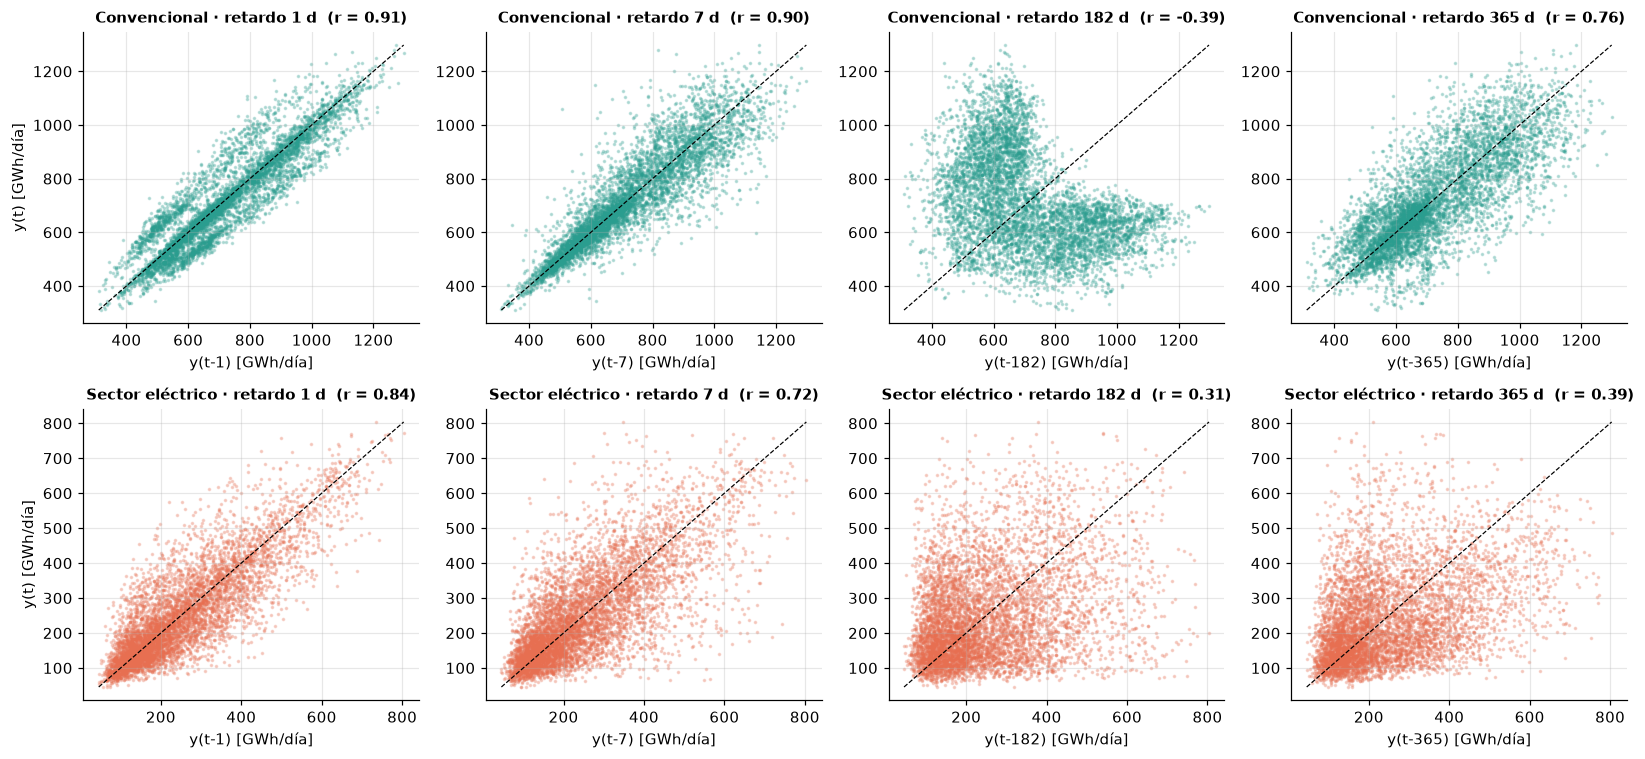

In [11]:
LAGS = [1, 7, 182, 365]
fig, axes = plt.subplots(2, len(LAGS), figsize=(15, 7))
for row, s in enumerate(["Convencional", "Sector eléctrico"]):
    x = daily[s]
    for col, k in enumerate(LAGS):
        ax = axes[row, col]
        ax.scatter(x.shift(k), x, s=2, alpha=0.25, color=COLORS[s])
        lim = [x.min(), x.max()]
        ax.plot(lim, lim, color="black", lw=0.8, ls="--")
        ax.set(title=f"{s} · retardo {k} d  (r = {x.autocorr(k):.2f})",
               xlabel=f"y(t-{k}) [GWh/día]", ylabel="y(t) [GWh/día]" if col == 0 else "")
        ax.title.set_fontsize(10)
plt.tight_layout()
plt.show()

**Lectura.**
- **Retardo 1 día:** la correlación es muy alta (0,91 en la convencional y 0,84 en la eléctrica): la demanda de hoy se parece mucho a la de ayer. En la convencional se ven **dos nubes paralelas**, que corresponden a los saltos de viernes a sábado y de domingo a lunes.
- **Retardo 7 días:** en la convencional la correlación (0,90) es casi igual que con un día, porque el mismo día de la semana anterior elimina el efecto laboral. En la eléctrica baja a 0,72.
- **Retardo 182 días (medio año):** correlación **negativa** en la convencional (−0,39), porque invierno y verano son opuestos.
- **Retardo 365 días:** en la convencional el año anterior es un buen predictor (0,76). En la eléctrica no (0,39). **Esto anticipa el resultado del bloque D: el seasonal naïve funcionará bien en la convencional y mal en la eléctrica.**

### B.4 · Función de autocorrelación (ACF)

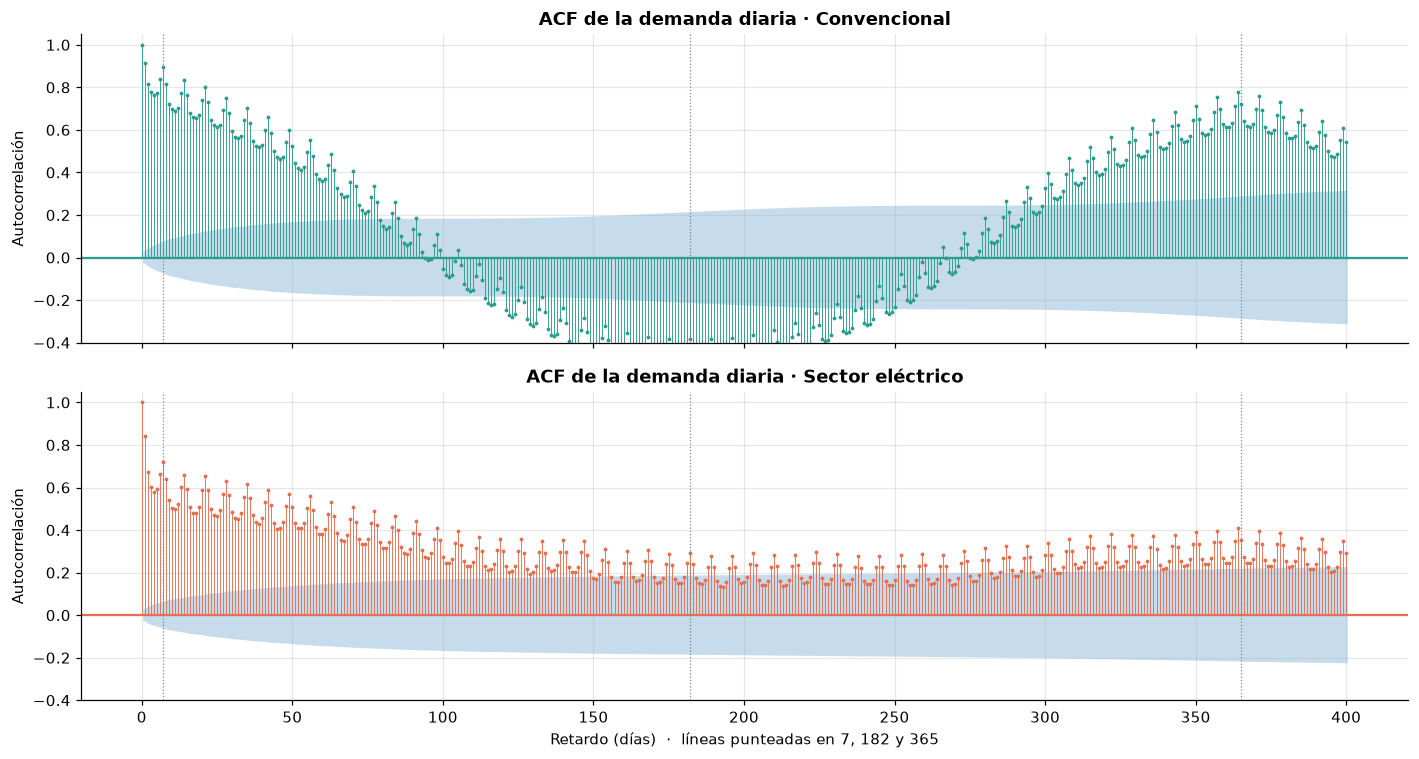

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, s in zip(axes, ["Convencional", "Sector eléctrico"]):
    plot_acf(daily[s], lags=400, ax=ax, markersize=1.5, color=COLORS[s], vlines_kwargs={"colors": COLORS[s], "lw": 0.6})
    for k in (7, 182, 365):
        ax.axvline(k, color="grey", ls=":", lw=0.8)
    ax.set(title=f"ACF de la demanda diaria · {s}", ylabel="Autocorrelación", ylim=(-0.4, 1.05))
axes[-1].set_xlabel("Retardo (días)  ·  líneas punteadas en 7, 182 y 365")
plt.tight_layout()
plt.show()

**Lectura.** La ACF de la convencional tiene la forma típica de una serie con **tendencia y estacionalidad**: decae despacio, con picos en los múltiplos de 7 (el patrón semanal) y una onda anual que se hace negativa alrededor del día 182 y vuelve a ser positiva cerca del 365. La del sector eléctrico también decae despacio, porque su nivel es muy persistente, pero **la onda anual apenas se aprecia**: su "memoria" es de nivel y no de calendario.

### B.5 · ¿Se comportan igual los dos componentes? ¿Qué pasó en 2022?

In [13]:
yoy = annual_twh.loc[2019:2025, ["Total", "Convencional", "Sector eléctrico"]]
pd.concat({"TWh": yoy.round(1), "Var. interanual (%)": (yoy.pct_change() * 100).round(1)}, axis=1)

TWh                               Var. interanual (%)               \
      Total Convencional Sector eléctrico               Total Convencional   
ds                                                                           
2019 397.90       286.80           111.10                 NaN          NaN   
2020 359.90       271.10            88.70               -9.60        -5.50   
2021 378.30       288.00            90.30                5.10         6.20   
2022 364.30       226.40           137.90               -3.70       -21.40   
2023 325.60       230.00            95.60              -10.60         1.60   
2024 311.80       237.10            74.70               -4.20         3.10   
2025 331.40       231.80            99.70                6.30        -2.30   

                       
     Sector eléctrico  
ds                     
2019              NaN  
2020           -20.10  
2021             1.70  
2022            52.80  
2023           -30.70  
2024           -21.80  
2025            33.40

**No se comportan igual, y 2022 es el ejemplo más claro: los dos componentes se movieron en sentidos opuestos.**

- **Convencional: −21,4 % (de 288 a 226 TWh).** Es la **destrucción de demanda por precio**. Con el TTF por encima de 100 €/MWh durante meses (y con picos de más de 300 €/MWh en agosto), la industria redujo producción o cambió de combustible, y hogares y comercios recortaron consumo. A esto se sumaron un otoño cálido y las medidas de ahorro (Real Decreto-ley 14/2022 y el compromiso europeo de reducir un 15 % el consumo). **La demanda convencional nunca ha recuperado el nivel anterior.**
- **Sector eléctrico: +52,8 % (de 90 a 138 TWh).** La sequía hundió la hidráulica, el parque nuclear francés estaba en mínimos, así que España exportó electricidad, y el "mecanismo ibérico" limitó el precio del gas para generar. Los ciclos combinados cubrieron el hueco.
- **Total: solo −3,7 %.** Los dos efectos casi se compensan, y **mirar solo el total habría ocultado dos cambios enormes de signo contrario**.

**Por qué importa para este invierno.** 2022 es el antecedente más cercano a la situación actual (shock de oferta y precios altos). Muestra que un precio alto reduce la demanda convencional, pero que la eléctrica puede dispararse si coinciden poca hidráulica y poca eólica. Por eso **las dos componentes tienen que vigilarse por separado**.

<a id="C"></a>
## C · Descomponer

### C.1 · Agregación mensual: ¿suma o media diaria?

El Ministerio necesita **TWh/mes**, que es la suma mensual. Pero la suma mezcla dos cosas: cuánto gas se consume al día y **cuántos días tiene el mes**. Un febrero de 28 días "consume" un 10 % menos que un enero de 31 aunque haga el mismo frío.

**Decisión:** modelizamos la **media diaria mensual (GWh/día)**, que corrige el calendario, y después convertimos a TWh/mes multiplicando por los días de cada mes. Así los métodos no confunden la duración del mes con la demanda y el resultado se expresa en la unidad que pide el negocio.

,Suma TWh/mes,Media GWh/día,Feb vs ene (%),"Feb vs ene, media (%)"
Enero,36.70,"1,184.01",0.00,0.00
Febrero,31.96,"1,132.79",-12.92,-4.33
Marzo,30.62,987.67,-16.58,-16.58


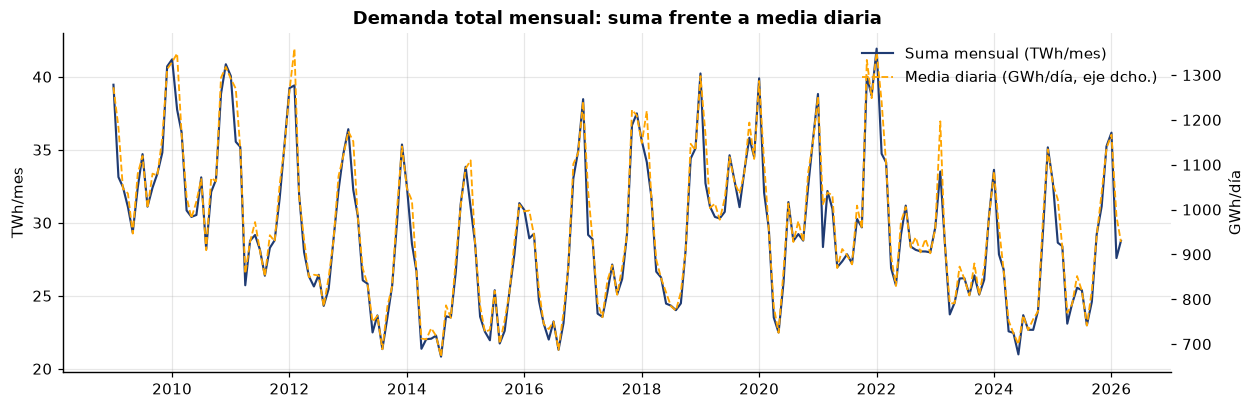

Serie mensual: ene-2009 a mar-2026 (207 meses por serie)


In [14]:
# Media diaria mensual (GWh/día): base de modelización, libre del efecto de la duración del mes
monthly_mean = daily.resample("MS").mean()
days_in_month = monthly_mean.index.days_in_month.values
monthly_twh = monthly_mean.mul(days_in_month, axis=0) / 1_000      # TWh/mes = media diaria × días

# ¿Cuánto pesa el calendario? Febrero frente a enero y marzo, en suma y en media diaria
feb = pd.DataFrame({
    "Suma TWh/mes": monthly_twh["Total"].groupby(monthly_twh.index.month).mean(),
    "Media GWh/día": monthly_mean["Total"].groupby(monthly_mean.index.month).mean(),
}).loc[[1, 2, 3]].set_axis(["Enero", "Febrero", "Marzo"])
feb["Feb vs ene (%)"] = (feb.iloc[:, 0] / feb.iloc[0, 0] - 1) * 100
feb["Feb vs ene, media (%)"] = (feb.iloc[:, 1] / feb.iloc[0, 1] - 1) * 100
display(feb.round(2))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(monthly_twh.index, monthly_twh["Total"], color=COLORS["Total"], lw=1.4, label="Suma mensual (TWh/mes)")
ax2 = ax.twinx()
ax2.plot(monthly_mean.index, monthly_mean["Total"], color="orange", lw=1.2, ls="--", label="Media diaria (GWh/día, eje dcho.)")
ax.set(title="Demanda total mensual: suma frente a media diaria", ylabel="TWh/mes")
ax2.set_ylabel("GWh/día")
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()

Y_month = (monthly_mean.reset_index().melt(id_vars="ds", var_name="unique_id", value_name="y")
           [["unique_id", "ds", "y"]].sort_values(["unique_id", "ds"], ignore_index=True))
print(f"Serie mensual: {mes(monthly_mean.index.min())} a {mes(monthly_mean.index.max())} ({len(monthly_mean)} meses por serie)")

**Lectura.** En suma mensual, febrero sale un **12,9 % por debajo de enero**; en media diaria la diferencia es solo del **4,3 %**. **Casi 9 puntos de esa caída son puro calendario**, no menor consumo. Si modelizáramos la suma, el componente estacional de febrero absorbería el efecto de los días (y no recogería bien los febreros bisiestos). Con la media diaria, la estacionalidad refleja solo el clima y la actividad.

### C.2 · ¿Hace falta una transformación de Box-Cox?

Box-Cox se justifica cuando **la amplitud estacional crece con el nivel** de la serie. Lo comprobamos de dos formas: con el λ de Guerrero y con la relación entre la media anual y la dispersión dentro del año.

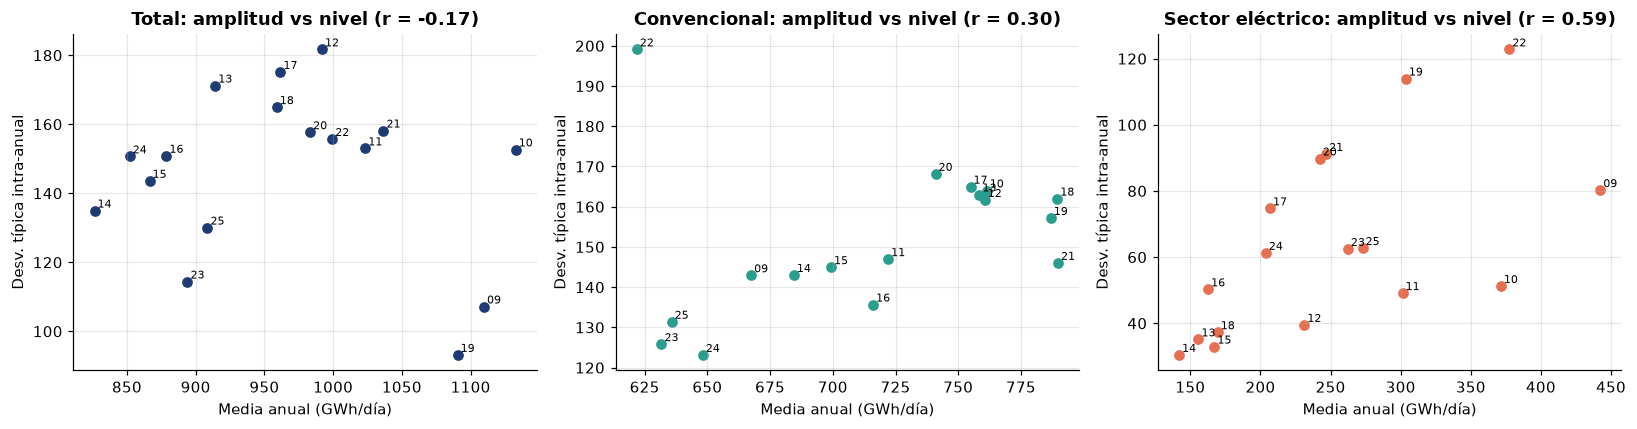

,λ Guerrero,Corr. nivel-amplitud,CV intra-anual mín.,CV intra-anual máx.
Total,0.31,-0.17,0.09,0.19
Convencional,0.28,0.30,0.18,0.32
Sector eléctrico,0.28,0.59,0.14,0.38


In [15]:
# 1) λ de Guerrero (elige λ que estabiliza el cociente desviación/nivel entre años)
lambdas = pd.Series({s: boxcox_lambda(monthly_mean[s].values, method="guerrero", season_length=12) for s in SERIES},
                    name="λ Guerrero")

# 2) Diagnóstico visual: ¿crece la amplitud estacional con el nivel?
stats_year = monthly_mean.groupby(monthly_mean.index.year).agg(["mean", "std"]).loc[:2025]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, SERIES):
    m, sd = stats_year[(s, "mean")], stats_year[(s, "std")]
    ax.scatter(m, sd, color=COLORS[s])
    for yr in m.index:
        ax.annotate(str(yr)[2:], (m[yr], sd[yr]), fontsize=7, xytext=(2, 2), textcoords="offset points")
    corr = np.corrcoef(m, sd)[0, 1]
    ax.set(title=f"{s}: amplitud vs nivel (r = {corr:.2f})", xlabel="Media anual (GWh/día)", ylabel="Desv. típica intra-anual")
plt.tight_layout()
plt.show()

cv = (stats_year.xs("std", axis=1, level=1) / stats_year.xs("mean", axis=1, level=1))
pd.DataFrame({"λ Guerrero": lambdas, "Corr. nivel-amplitud": [np.corrcoef(stats_year[(s, 'mean')], stats_year[(s, 'std')])[0, 1] for s in SERIES],
              "CV intra-anual mín.": cv.min(), "CV intra-anual máx.": cv.max()}).round(2)

**Decisión razonada: no aplicamos Box-Cox en esta fase.**
- **Total:** no hay relación entre nivel y amplitud (r = −0,17). La serie es claramente aditiva.
- **Convencional:** la relación es débil (r = 0,30) y la provoca sobre todo un punto, 2022, con nivel bajo y mucha dispersión, que va **en contra** de la hipótesis multiplicativa.
- **Sector eléctrico:** aquí sí hay relación (r = 0,59): los años con más gas tienen más variación. Es el único caso en que Box-Cox tendría sentido (λ de Guerrero ≈ 0,3).
- **Aun así, en este bloque no cambia nada:** los métodos naïve y seasonal naïve dan la misma predicción puntual con o sin transformación (copian un valor y la transformación inversa lo devuelve tal cual). Solo cambiarían la media y la deriva, y de forma marginal. Además, transformar complica sumar componentes y totales en TWh.

**Lo retomaremos** en las fases de ETS y ARIMA para el sector eléctrico, donde la transformación sí afecta a los intervalos.

### C.3 · Descomposición clásica frente a STL (serie mensual)

- **Clásica:** calcula la tendencia con una media móvil 2×12, que pierde 6 meses en cada extremo, y supone un **patrón estacional idéntico todos los años**.
- **STL robusta:** usa regresión local (LOESS), conserva todos los meses, deja que la estacionalidad **evolucione** y es resistente a los atípicos, como el año 2022.

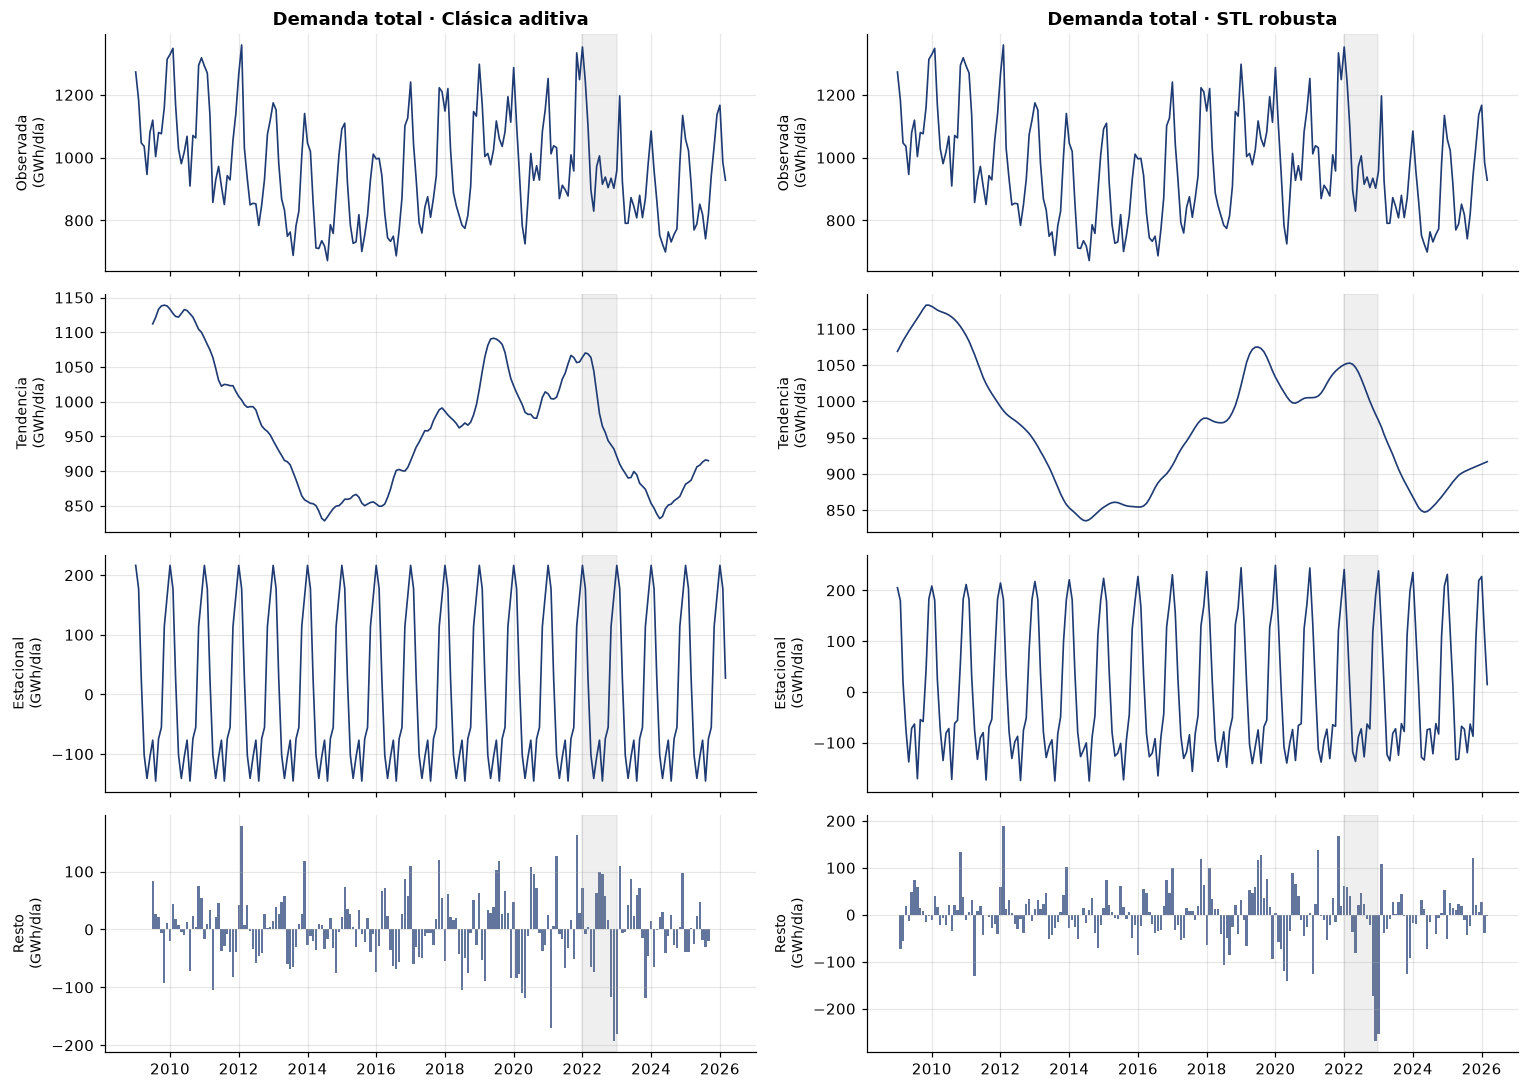

In [16]:
# Descomposición clásica (medias móviles 2x12) frente a STL robusta, sobre la media diaria mensual
def decompose_both(s):
    x = monthly_mean[s]
    classical = seasonal_decompose(x, model="additive", period=12)
    stl = STL(x, period=12, seasonal=13, robust=True).fit()
    return classical, stl

fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
classical, stl = decompose_both("Total")
for col, (name, res) in enumerate([("Clásica aditiva", classical), ("STL robusta", stl)]):
    for row, (comp, label) in enumerate([("observed", "Observada"), ("trend", "Tendencia"),
                                         ("seasonal", "Estacional"), ("resid", "Resto")]):
        ax = axes[row, col]
        vals = getattr(res, comp)
        if comp == "resid":
            ax.bar(vals.index, vals, width=25, color=COLORS["Total"], alpha=0.7)
        else:
            ax.plot(vals.index, vals, color=COLORS["Total"], lw=1.1)
        ax.set_ylabel(f"{label}\n(GWh/día)", fontsize=9)
        if row == 0:
            ax.set_title(f"Demanda total · {name}")
        ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="grey", alpha=0.12)
plt.tight_layout()
plt.show()

**Lectura de la demanda total.** Las dos descomposiciones coinciden a grandes rasgos: una tendencia que baja hasta 2014, sube hasta 2019-2021 y vuelve a caer, más una estacionalidad de unos ±180 GWh/día. Las diferencias importantes son tres:
1. **La clásica no tiene tendencia en los últimos 6 meses**, justo los más recientes y los que más interesan para predecir. La STL sí la tiene.
2. **La clásica impone la misma estacionalidad en 2010 y en 2025.** La STL deja que cambie, lo que importa porque la estructura de la demanda ha cambiado.
3. **En 2022 la clásica "contamina" la estacionalidad** de toda la serie con un año anómalo. La STL robusta lo deja en el resto.

In [17]:
def strength(trend, seasonal, resid):
    """Fuerza de tendencia y estacionalidad (Hyndman & Athanasopoulos, FPP3 §4.3)."""
    ok = ~(np.isnan(trend) | np.isnan(resid))
    t, se, r = trend[ok], seasonal[ok], resid[ok]
    return max(0, 1 - np.var(r) / np.var(t + r)), max(0, 1 - np.var(r) / np.var(se + r))

rows = []
for s in SERIES:
    classical, stl = decompose_both(s)
    for name, res in [("Clásica", classical), ("STL", stl)]:
        ft, fs = strength(res.trend.values, res.seasonal.values, res.resid.values)
        resid = res.resid.dropna()
        # ¿cuánto cambia el patrón estacional entre el principio y el final de la muestra?
        seas = res.seasonal.groupby(res.seasonal.index.year).agg(lambda v: v.max() - v.min())
        rows.append({"Serie": s, "Método": name, "F tendencia": ft, "F estacional": fs,
                     "Desv. resto (GWh/día)": resid.std(), "Meses sin tendencia": res.trend.isna().sum(),
                     "Amplitud estacional 2010": seas.loc[2010], "Amplitud estacional 2025": seas.loc[2025]})
pd.DataFrame(rows).set_index(["Serie", "Método"]).round(2)

F tendencia  F estacional  Desv. resto (GWh/día)  \
Serie            Método                                                      
Total            Clásica         0.71          0.82                  59.44   
                 STL             0.70          0.82                  59.14   
Convencional     Clásica         0.75          0.94                  34.50   
                 STL             0.68          0.93                  39.39   
Sector eléctrico Clásica         0.76          0.51                  45.15   
                 STL             0.71          0.44                  52.45   

                          Meses sin tendencia  Amplitud estacional 2010  \
Serie            Método                                                   
Total            Clásica                   12                    361.56   
                 STL                        0                    380.77   
Convencional     Clásica                   12                    429.22   
                 STL                        0                    449.84   
Sector eléctrico Clásica                   12                    136.69   
                 STL                        0                    148.94   

                          Amplitud estacional 2025  
Serie            Método                             
Total            Clásica                    361.56  
                 STL                        364.92  
Convencional     Clásica                    429.22  
                 STL                        393.59  
Sector eléctrico Clásica                    136.69  
                 STL                        133.90

**Lectura de la comparación.**
- La **fuerza estacional** (F, de 0 a 1) confirma lo que se veía en los gráficos: la convencional es casi pura estacionalidad (F = 0,93); el sector eléctrico tiene una estacionalidad débil (F = 0,44 en STL) y el total queda en medio (0,82).
- La STL muestra que la **amplitud estacional de la convencional ha bajado de 450 a 394 GWh/día** entre 2010 y 2025, un 12 % menos. Los inviernos "pesan" menos que antes, por la mejora de la eficiencia y por los inviernos más templados. La clásica, que es constante por construcción, no puede verlo.
- **Elegimos STL** como descomposición mensual de referencia: no pierde los meses recientes, recoge la evolución del patrón estacional y es robusta frente a 2022.

### C.4 · MSTL sobre la serie diaria

La serie diaria tiene **dos estacionalidades a la vez**: la semanal (7 días) y la anual (365 días). La MSTL (STL múltiple, implementada en `statsforecast`) las separa de forma iterativa.

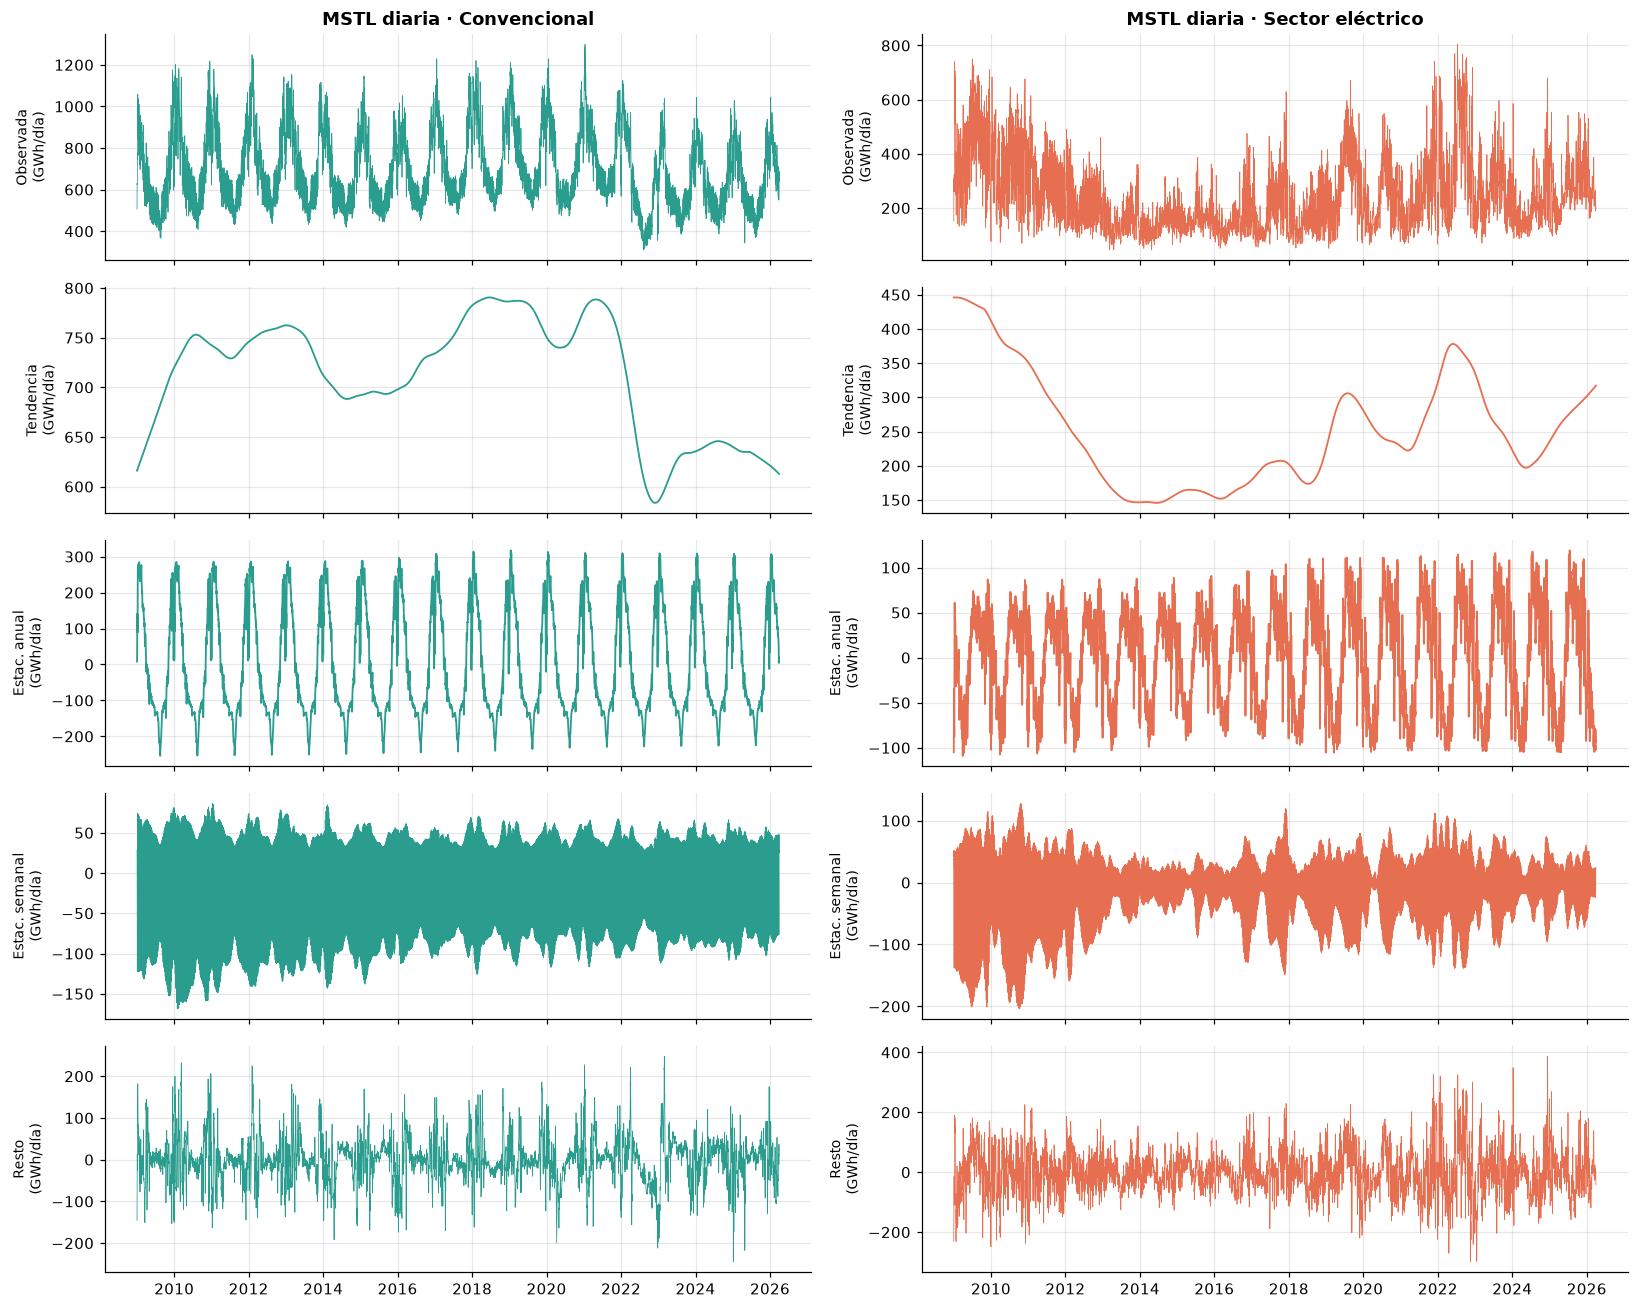

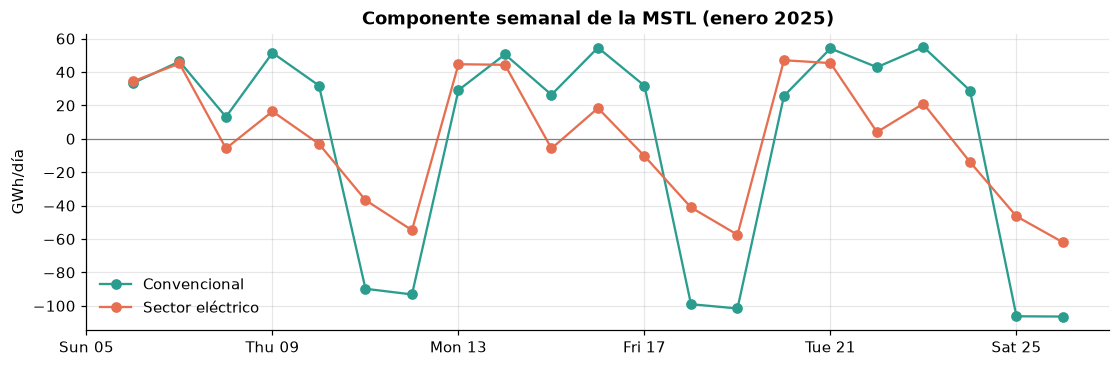

In [18]:
# MSTL sobre la serie diaria con dos estacionalidades: semanal (7) y anual (365)
sf_mstl = StatsForecast(models=[MSTL(season_length=[7, 365])], freq="D", n_jobs=1)
sf_mstl.fit(Y_daily)
mstl_comp = {uid: sf_mstl.fitted_[i, 0].model_.set_index(Y_daily.loc[Y_daily.unique_id == uid, "ds"].values)
             for i, uid in enumerate(sf_mstl.uids)}

fig, axes = plt.subplots(5, 2, figsize=(15, 12), sharex=True)
for col, s in enumerate(["Convencional", "Sector eléctrico"]):
    comp = mstl_comp[s]
    for row, (c, label) in enumerate([("data", "Observada"), ("trend", "Tendencia"), ("seasonal365", "Estac. anual"),
                                      ("seasonal7", "Estac. semanal"), ("remainder", "Resto")]):
        ax = axes[row, col]
        ax.plot(comp.index, comp[c], color=COLORS[s], lw=0.5 if c in ("data", "remainder", "seasonal7") else 1.2)
        ax.set_ylabel(f"{label}\n(GWh/día)", fontsize=9)
        if row == 0:
            ax.set_title(f"MSTL diaria · {s}")
plt.tight_layout()
plt.show()

# Zoom en tres semanas de enero de 2025 para ver la componente semanal
fig, ax = plt.subplots(figsize=(12, 3.5))
for s in ["Convencional", "Sector eléctrico"]:
    z = mstl_comp[s].loc["2025-01-06":"2025-01-26", "seasonal7"]
    ax.plot(z.index, z, marker="o", color=COLORS[s], label=s)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="Componente semanal de la MSTL (enero 2025)", ylabel="GWh/día")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
ax.legend()
plt.show()

**Lectura.**
- **Convencional:** la componente anual es enorme y muy regular (de −250 a +300 GWh/día). La tendencia muestra con claridad el **escalón de 2022**: de ~790 a ~600 GWh/día. Desde 2023 se estabiliza en torno a 630 y en 2026 baja ligeramente. La componente semanal oscila unos ±70 GWh/día y su amplitud se reduce con el tiempo.
- **Sector eléctrico:** la tendencia lleva casi toda la información: la caída de 2009-2014, los ciclos de 2019 y 2022 y una **subida sostenida desde 2024 que todavía continúa a finales de la muestra**, hasta unos 320 GWh/día en marzo de 2026. La componente anual es irregular y el resto es grande, con picos de ±300 GWh/día en 2022.
- En el zoom de enero se ve que la componente semanal alcanza su mínimo el domingo en ambas series, y que en la eléctrica es proporcionalmente más profunda.

### C.5 · ¿Qué parte de la variación es estacional y cuál es tendencia?

In [19]:
# Reparto de la variación: varianza de cada componente sobre la varianza de la serie
def var_share(comp, cols):
    v = comp[cols].var()
    return 100 * v / comp["data"].var()

mstl_share = pd.DataFrame({s: var_share(mstl_comp[s], ["trend", "seasonal365", "seasonal7", "remainder"]) for s in SERIES}).T
mstl_share.columns = ["Tendencia", "Estac. anual", "Estac. semanal", "Resto"]
mstl_share["F estacional anual"] = [max(0, 1 - mstl_comp[s]["remainder"].var() / (mstl_comp[s]["seasonal365"] + mstl_comp[s]["remainder"]).var()) for s in SERIES]
mstl_share["F tendencia"] = [max(0, 1 - mstl_comp[s]["remainder"].var() / (mstl_comp[s]["trend"] + mstl_comp[s]["remainder"]).var()) for s in SERIES]

stl_share = {}
for s in SERIES:
    _, stl = decompose_both(s)
    df_ = pd.DataFrame({"data": stl.observed, "trend": stl.trend, "seasonal": stl.seasonal, "remainder": stl.resid})
    stl_share[s] = var_share(df_, ["trend", "seasonal", "remainder"])
stl_share = pd.DataFrame(stl_share).T
stl_share.columns = ["Tendencia", "Estacional", "Resto"]

print("MSTL diaria — % de la varianza de la serie explicado por cada componente")
display(mstl_share.round(2))
print("STL mensual — % de la varianza de la serie")
display(stl_share.round(1))

MSTL diaria — % de la varianza de la serie explicado por cada componente


,Tendencia,Estac. anual,Estac. semanal,Resto,F estacional anual,F tendencia
Total,15.52,40.36,21.22,20.09,0.67,0.46
Convencional,10.48,70.22,11.00,9.08,0.88,0.57
Sector eléctrico,36.26,15.53,12.93,29.84,0.37,0.57


STL mensual — % de la varianza de la serie


,Tendencia,Estacional,Resto
Total,26.70,59.60,12.40
Convencional,10.60,78.90,6.30
Sector eléctrico,56.10,14.20,24.20


**Lectura de negocio.** Las proporciones no suman exactamente 100 % porque los componentes no son del todo independientes, pero el mensaje es claro:

| Serie | Lo que domina (MSTL diaria) | Lo que domina (STL mensual) | Implicación |
|---|---|---|---|
| **Convencional** | Estacionalidad anual (**70 %**) | Estacional **79 %**, tendencia 11 % | El calendario y el frío explican casi todo: **predecible**. |
| **Sector eléctrico** | Tendencia (**36 %**) y resto (**30 %**) | Tendencia **56 %**, estacional 14 % | Lo que importa es el **nivel** y sus cambios de régimen: **poco predecible** con métodos estacionales. |
| **Total** | Estac. anual 40 %, semanal 21 %, resto 20 % | Estacional 60 %, tendencia 27 % | Mezcla de los dos. |

Para el Ministerio esto significa que **el riesgo de equivocarse en la cifra del invierno no viene del calendario, sino del nivel de la demanda eléctrica**: si la tendencia del gas para generación sigue subiendo, un método que mire solo la estacionalidad se quedará corto.

<a id="D"></a>
## D · Fijar el listón

### D.1 · Partición temporal

Reservamos los **últimos 12 meses (abril de 2025 a marzo de 2026)** como conjunto de prueba. Los modelos se ajustan solo con datos hasta marzo de 2025, así que no hay fuga de información, y se predicen 12 meses de golpe, igual que haremos en el bloque F.

In [20]:
H = 12
test_start = Y_month["ds"].max() - pd.DateOffset(months=H - 1)
train = Y_month[Y_month["ds"] < test_start].reset_index(drop=True)
test = Y_month[Y_month["ds"] >= test_start].reset_index(drop=True)
print(f"Entrenamiento: {mes(train.ds.min())} – {mes(train.ds.max())}  ({train.groupby('unique_id').size().iloc[0]} meses)")
print(f"Prueba       : {mes(test.ds.min())} – {mes(test.ds.max())}  ({test.groupby('unique_id').size().iloc[0]} meses)")
assert train["ds"].max() < test["ds"].min(), "Fuga de información: el entrenamiento solapa con la prueba"

Entrenamiento: ene-2009 – mar-2025  (195 meses)
Prueba       : abr-2025 – mar-2026  (12 meses)


### D.2 · Cuatro métodos de referencia en las tres series

| Método | Predicción | Cuándo funciona |
|---|---|---|
| **Media** (`HistoricAverage`) | media de toda la historia | series sin tendencia ni estacionalidad |
| **Naïve** (`Naive`) | último valor observado | paseos aleatorios |
| **Seasonal naïve** (`SeasonalNaive(12)`) | mismo mes del año anterior | series dominadas por la estacionalidad |
| **Drift** (`RandomWalkWithDrift`) | último valor + pendiente media histórica | series con tendencia lineal |

Se ajustan sobre la media diaria mensual y la predicción se convierte a **TWh/mes**, la unidad en la que se evalúan los errores.

In [21]:
MODELS = [HistoricAverage(), Naive(), SeasonalNaive(season_length=12), RandomWalkWithDrift()]
MODEL_NAMES = ["HistoricAverage", "Naive", "SeasonalNaive", "RWD"]
LABELS = {"HistoricAverage": "Media", "Naive": "Naïve", "SeasonalNaive": "Seasonal naïve", "RWD": "Drift"}

sf = StatsForecast(models=MODELS, freq="MS", n_jobs=1)
fc_test = sf.forecast(df=train, h=H, fitted=True)
fitted_train = sf.forecast_fitted_values()

def to_twh(df, cols):
    """GWh/día (media mensual) -> TWh/mes, multiplicando por los días de cada mes."""
    out = df.copy()
    factor = out["ds"].dt.days_in_month / 1_000
    out[cols] = out[cols].mul(factor, axis=0)
    return out

eval_df = to_twh(test.merge(fc_test, on=["unique_id", "ds"]), ["y"] + MODEL_NAMES)
eval_df.head()

,unique_id,ds,y,HistoricAverage,Naive,SeasonalNaive,RWD
0,Convencional,2025-04-01,17.56,21.66,22.31,18.11,22.29
1,Convencional,2025-05-01,17.26,22.38,23.05,18.18,23.02
2,Convencional,2025-06-01,15.71,21.66,22.31,16.49,22.26
3,Convencional,2025-07-01,16.07,22.38,23.05,16.60,22.98
4,Convencional,2025-08-01,13.86,22.38,23.05,15.17,22.96


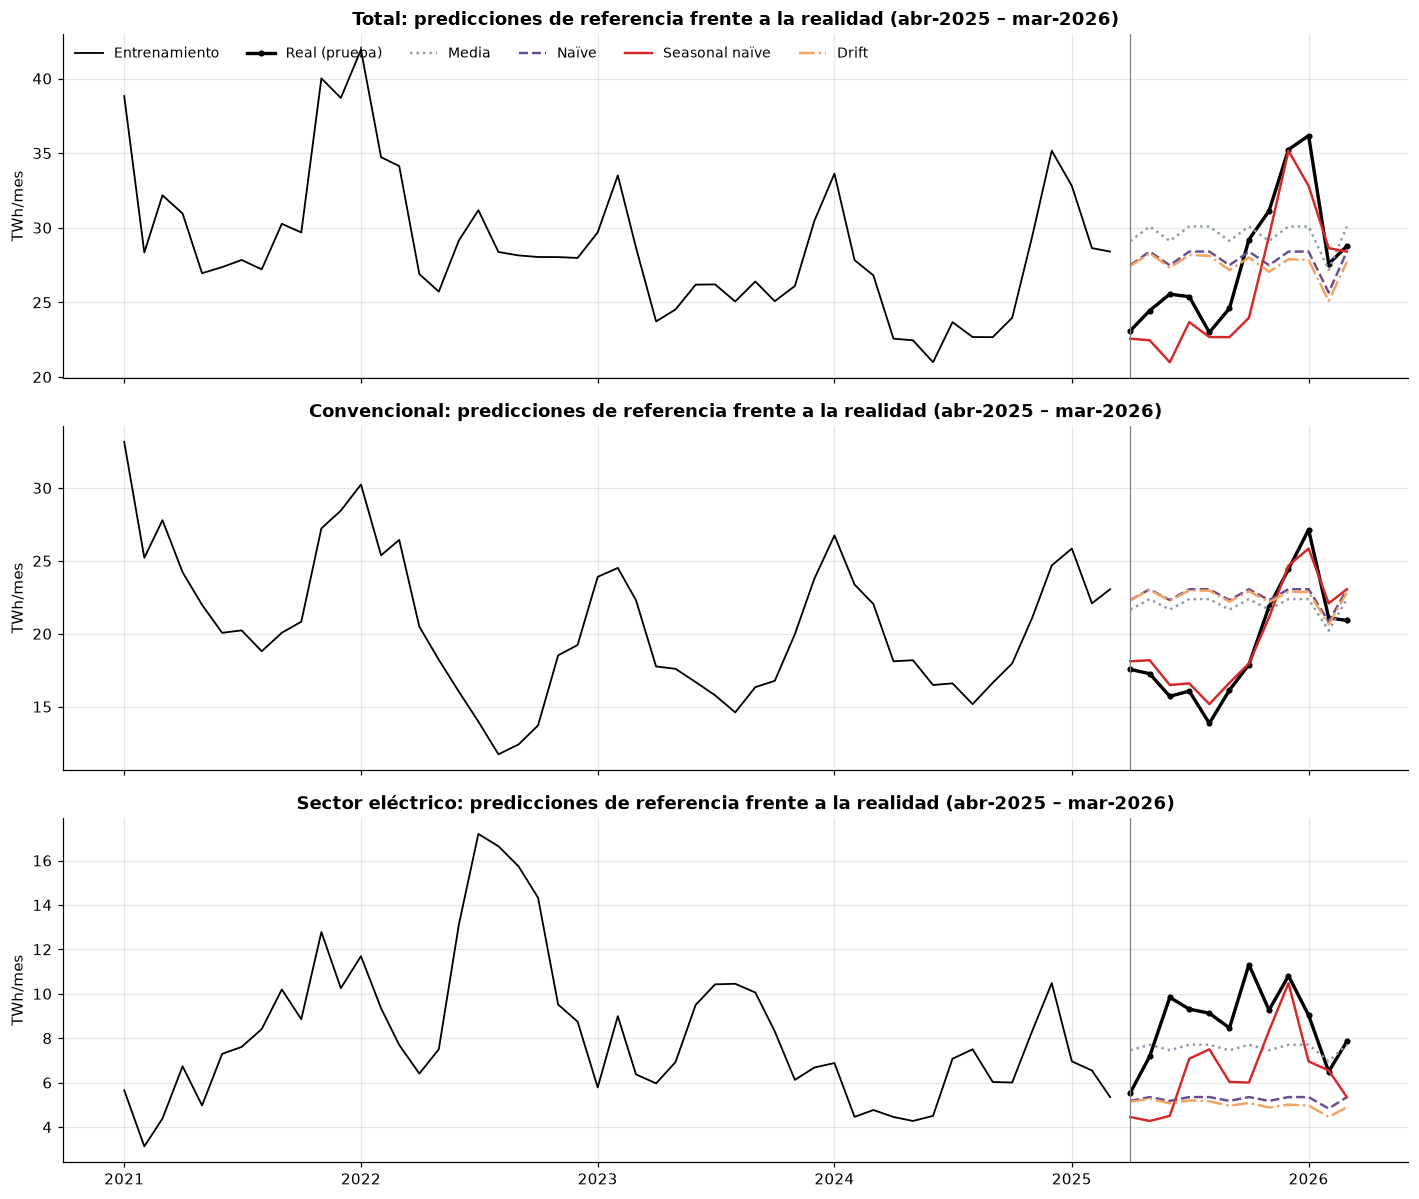

In [22]:
hist_twh = to_twh(train[train["ds"] >= "2021-01-01"], ["y"])
STYLE = {"HistoricAverage": ("#8d99ae", ":"), "Naive": ("#6a4c93", "--"), "SeasonalNaive": ("#d62828", "-"), "RWD": ("#f4a261", "-.")}

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for ax, s in zip(axes, SERIES):
    h, e = hist_twh[hist_twh.unique_id == s], eval_df[eval_df.unique_id == s]
    ax.plot(h["ds"], h["y"], color="black", lw=1.2, label="Entrenamiento")
    ax.plot(e["ds"], e["y"], color="black", lw=2.2, marker="o", ms=3, label="Real (prueba)")
    for m in MODEL_NAMES:
        c, ls = STYLE[m]
        ax.plot(e["ds"], e[m], color=c, ls=ls, lw=1.6, label=LABELS[m])
    ax.axvline(test_start, color="grey", lw=0.8)
    ax.set(title=f"{s}: predicciones de referencia frente a la realidad (abr-2025 – mar-2026)", ylabel="TWh/mes")
axes[0].legend(ncol=6, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura.** En la demanda **total** y en la **convencional** solo el seasonal naïve sigue la forma de la realidad (el valle de verano y el pico de diciembre-enero); los otros tres métodos dibujan líneas casi planas. En el **sector eléctrico** ningún método acierta: la demanda real (6-11 TWh/mes) queda por encima de todos, porque el año de prueba coincide con la subida del 33 % del gas para generación. La media se acerca más por casualidad: el promedio de 2009-2025 (~7,6 TWh/mes) es mayor que el último año de entrenamiento.

In [23]:
scores = evaluate(eval_df, metrics=[mae, rmse, mape], models=MODEL_NAMES)
scores = scores.melt(id_vars=["unique_id", "metric"], var_name="Modelo", value_name="valor")
scores["Modelo"] = scores["Modelo"].map(LABELS)
scores.loc[scores.metric == "mape", "valor"] *= 100
table = scores.pivot_table(index=["unique_id", "Modelo"], columns="metric", values="valor")
table = table.rename(columns={"mae": "MAE (TWh/mes)", "rmse": "RMSE (TWh/mes)", "mape": "MAPE (%)"})
table = table.reindex(SERIES, level=0)[["MAE (TWh/mes)", "RMSE (TWh/mes)", "MAPE (%)"]]

# Ganador por serie según MAE (la métrica en la misma unidad que el negocio)
best = (scores[scores.metric == "mae"].sort_values("valor").groupby("unique_id").first()["Modelo"])
best_model = {s: next(k for k, v in LABELS.items() if v == best[s]) for s in SERIES}

# Error anual agregado de la prueba (lo que importa para el aprovisionamiento)
annual_err = eval_df.groupby("unique_id")[["y"] + MODEL_NAMES].sum()
annual_err = annual_err[MODEL_NAMES].sub(annual_err["y"], axis=0).rename(columns=LABELS).reindex(SERIES)

display(table.round(2))
print("Ganador (menor MAE) por serie:", {s: LABELS[m] for s, m in best_model.items()})
print("\nSesgo acumulado en los 12 meses de prueba (predicho − real, TWh):")
display(annual_err.round(1))

metric                           MAE (TWh/mes)  RMSE (TWh/mes)  MAPE (%)
unique_id        Modelo                                                 
Total            Drift                    3.75            4.34     13.25
                 Media                    3.95            4.51     14.83
                 Naïve                    3.58            4.19     12.80
                 Seasonal naïve           1.90            2.49      6.85
Convencional     Drift                    4.39            5.13     25.93
                 Media                    4.11            4.75     24.08
                 Naïve                    4.42            5.17     26.15
                 Seasonal naïve           0.84            1.00      4.49
Sector eléctrico Drift                    3.68            4.01     40.13
                 Media                    1.61            1.90     17.90
                 Naïve                    3.44            3.77     37.32
                 Seasonal naïve           2.24            2.76     25.05

Ganador (menor MAE) por serie: {'Total': 'Seasonal naïve', 'Convencional': 'Seasonal naïve', 'Sector eléctrico': 'Media'}

Sesgo acumulado en los 12 meses de prueba (predicho − real, TWh):


,Media,Naïve,Seasonal naïve,Drift
unique_id,,,,
Total,20.10,0.30,-20.70,-4.10
Convencional,33.60,41.50,6.00,40.10
Sector eléctrico,-13.50,-41.20,-26.70,-44.10


**El rival a batir en cada serie:**

| Serie | Ganador | MAE | MAPE | Comentario |
|---|---|---|---|---|
| **Total** | **Seasonal naïve** | 1,90 TWh/mes | 6,9 % | La mitad de error que el siguiente método (naïve, 3,58). |
| **Convencional** | **Seasonal naïve** | 0,84 TWh/mes | 4,5 % | Un listón muy exigente: solo superable con información de temperatura. |
| **Sector eléctrico** | **Media** | 1,61 TWh/mes | 17,9 % | Gana porque falla menos, no porque acierte. Sigue infraestimando 13,5 TWh al año. |

**El sesgo acumulado importa tanto como el MAE.** En 12 meses, el seasonal naïve de la demanda total **se queda corto en 20,7 TWh** (un 6 % del consumo anual). Todo ese hueco viene del sector eléctrico (−26,7 TWh); la convencional incluso se sobreestima (+6 TWh). Con la frase del enunciado: *si la demanda se subestima, el invierno se paga caro*. El riesgo de los métodos de referencia está en **el gas para generación**.

<a id="E"></a>
## E · Diagnosticar los residuos

Analizamos los residuos dentro de la muestra de entrenamiento del mejor método de cada serie. Si el método hubiera aprovechado toda la información, los residuos serían **ruido blanco**: sin autocorrelación, con media cero y aproximadamente normales.

In [24]:
def residual_diagnostics(uid, model):
    r = fitted_train[fitted_train.unique_id == uid].set_index("ds")
    resid = (r["y"] - r[model]).dropna()
    lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)

    fig = plt.figure(figsize=(14, 6.5))
    gs = fig.add_gridspec(2, 2)
    ax0 = fig.add_subplot(gs[0, :])
    ax0.plot(resid.index, resid, color=COLORS[uid], lw=0.9)
    ax0.axhline(0, color="black", lw=0.8)
    ax0.set(title=f"{uid} · residuos del {LABELS[model]} (entrenamiento)", ylabel="GWh/día")
    ax1 = fig.add_subplot(gs[1, 0])
    plot_acf(resid, lags=36, ax=ax1, color=COLORS[uid], vlines_kwargs={"colors": COLORS[uid]})
    ax1.set(title="ACF de los residuos", xlabel="Retardo (meses)", ylim=(-0.6, 1.05))
    ax2 = fig.add_subplot(gs[1, 1])
    ax2.hist(resid, bins=30, color=COLORS[uid], alpha=0.8, edgecolor="white")
    ax2.axvline(resid.mean(), color="black", ls="--", lw=1, label=f"media = {resid.mean():.1f}")
    ax2.set(title="Histograma de los residuos", xlabel="GWh/día", ylabel="Frecuencia")
    ax2.legend()
    plt.tight_layout()
    plt.show()

    acf_vals = pd.Series([resid.autocorr(k) for k in (1, 2, 12)], index=["r1", "r2", "r12"])
    return pd.Series({"Modelo": LABELS[model], "Media resid.": resid.mean(), "Desv. resid.": resid.std(),
                      **acf_vals.to_dict(),
                      "Q Ljung-Box (24)": lb.loc[24, "lb_stat"], "p-valor (24)": lb.loc[24, "lb_pvalue"]}, name=uid)

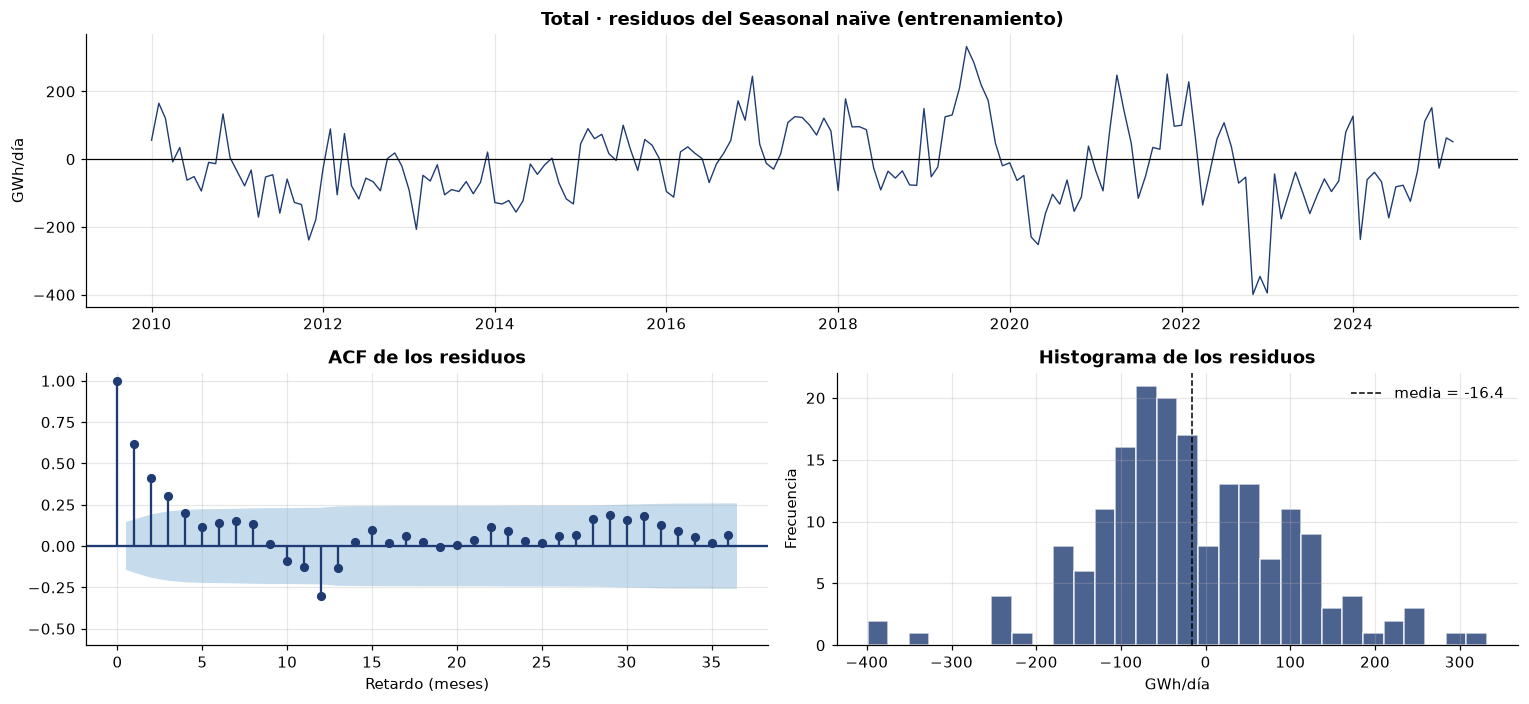

In [25]:
diag = {}
diag["Total"] = residual_diagnostics("Total", best_model["Total"])

**Total · seasonal naïve.** Los residuos tienen **rachas largas** del mismo signo: 2017-2019 y 2021 positivos; 2020, 2022-2023 y 2024 negativos. La ACF es alta en los primeros retardos (r₁ = 0,62, r₂ = 0,42) y negativa en el 12 (−0,31). La media es ligeramente negativa y la distribución tiene una cola izquierda, con los meses de finales de 2022.

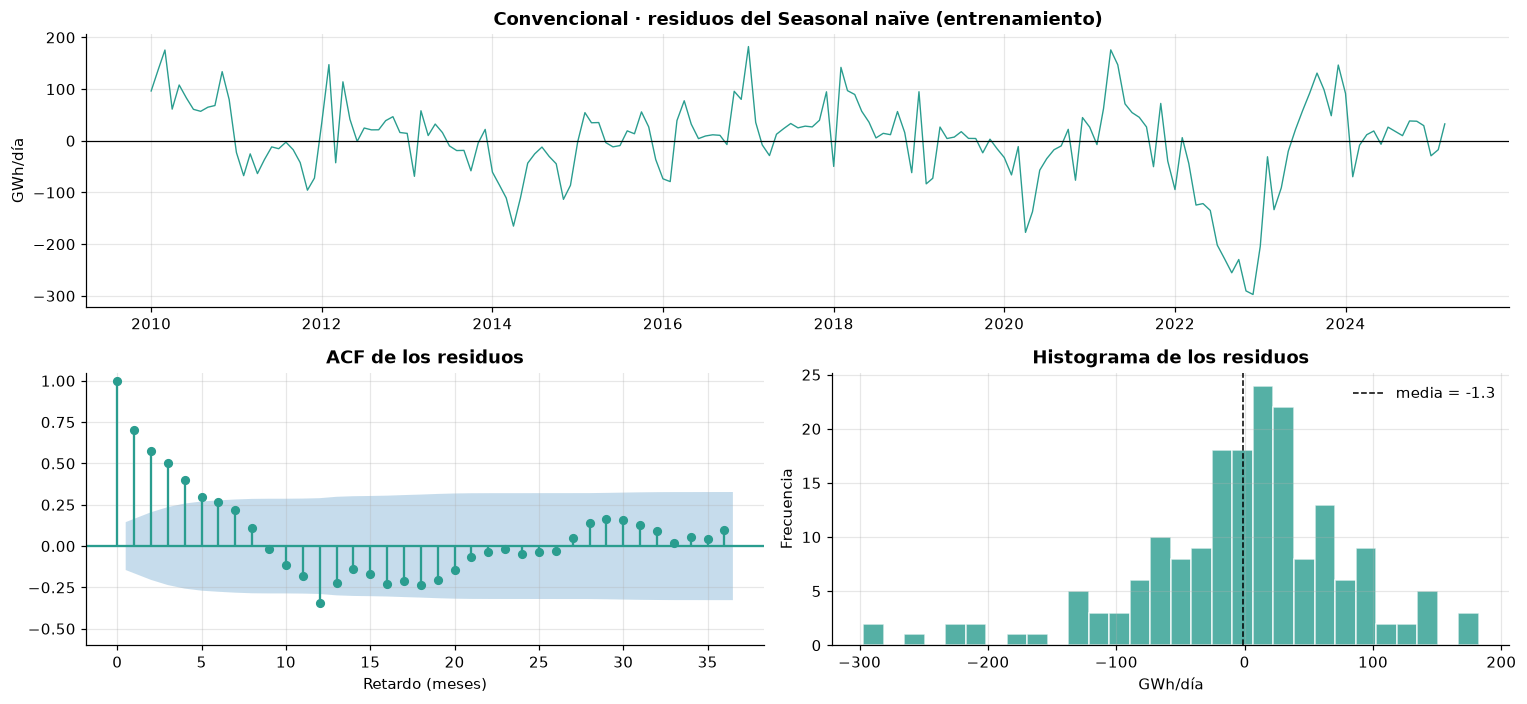

In [26]:
diag["Convencional"] = residual_diagnostics("Convencional", best_model["Convencional"])

**Convencional · seasonal naïve.** El patrón es el mismo pero más acusado (r₁ = 0,71). El retardo 12 negativo (−0,37) es la firma típica del seasonal naïve: **copia el ruido del año anterior**. Si el invierno pasado fue anormalmente frío, la predicción hereda ese frío y falla en sentido contrario.

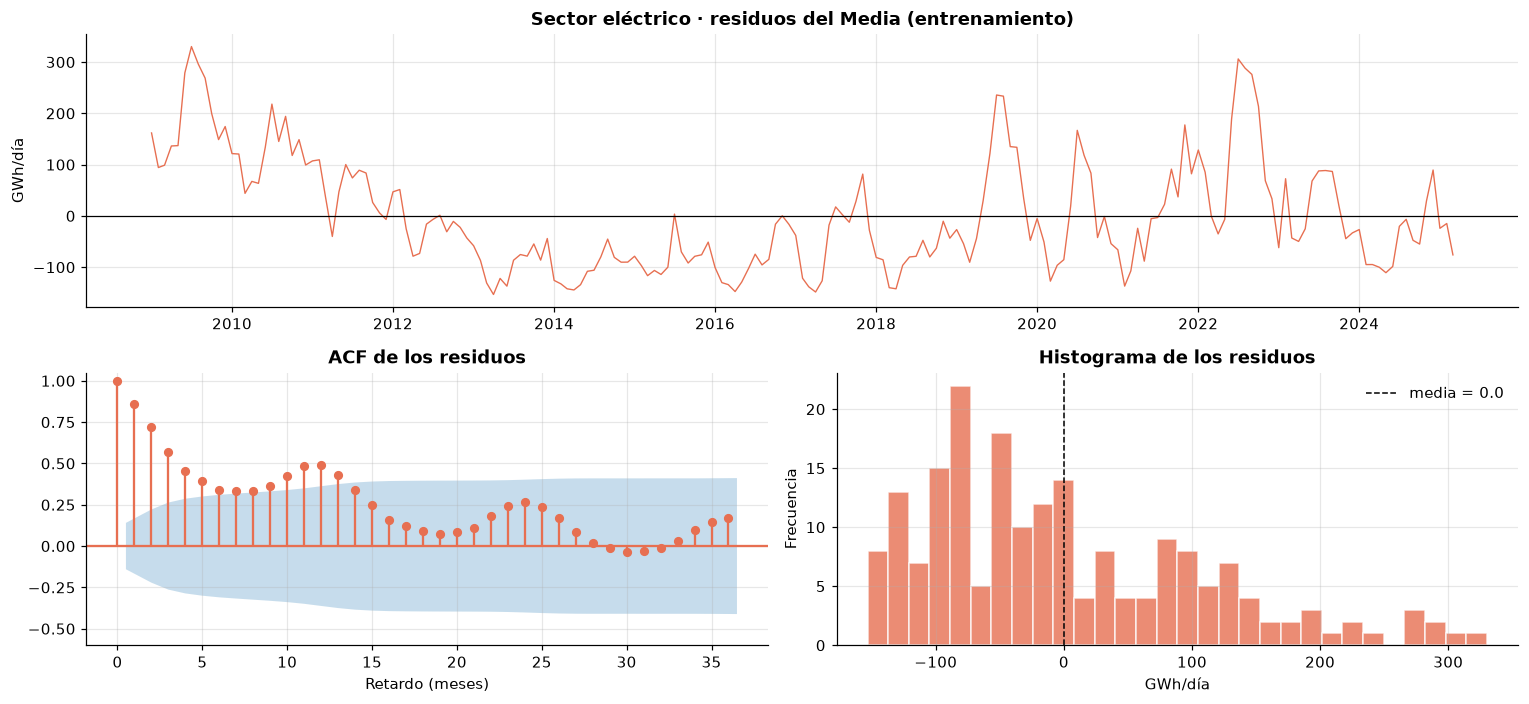

,Modelo,Media resid.,Desv. resid.,r1,r2,r12,Q Ljung-Box (24),p-valor (24)
Total,Seasonal naïve,-16.42,117.08,0.62,0.42,-0.31,176.26,0.00
Convencional,Seasonal naïve,-1.34,81.61,0.71,0.58,-0.37,371.50,0.00
Sector eléctrico,Media,0.00,108.83,0.87,0.73,0.57,749.41,0.00


In [27]:
diag["Sector eléctrico"] = residual_diagnostics("Sector eléctrico", best_model["Sector eléctrico"])
pd.DataFrame(diag).T.round(3)

**Sector eléctrico · media.** Es el caso más claro de información sin usar. Los residuos de la media son la propia serie centrada: autocorrelación muy alta (r₁ = 0,87) y además **autocorrelación anual positiva (r₁₂ = 0,57)**. La media ignora a la vez el nivel reciente y la estacionalidad.

### ¿Qué información han dejado sin usar los métodos de referencia?

En las tres series **el contraste de Ljung-Box (24 retardos) rechaza el ruido blanco con p < 0,001**. La información que queda en los residuos es de cuatro tipos:

1. **Persistencia de corto plazo (r₁ entre 0,6 y 0,9).** Si este mes la demanda está por encima de lo normal, el siguiente probablemente también. Ningún método de referencia combina la memoria del mes anterior con la estacionalidad; es justo lo que harán ETS y ARIMA (X6-X8).
2. **Cambios de nivel o tendencia,** sobre todo en el sector eléctrico. El escalón de 2022 en la convencional y la subida desde 2024 en la eléctrica aparecen como rachas largas de residuos del mismo signo.
3. **Ruido estacional heredado** (r₁₂ negativo en el seasonal naïve). Promediar varios años o suavizar la estacionalidad, como hace un ETS estacional, lo reduciría.
4. **Variables externas que los residuos delatan pero los modelos univariantes no pueden ver:** la **temperatura** (que mueve la convencional; se incorporará en la fase X9), la producción **hidráulica y eólica** y el **precio del gas**. Los residuos más grandes coinciden con 2022.

**Consecuencia práctica:** los intervalos de predicción de estos métodos suponen residuos independientes, así que **probablemente subestiman la incertidumbre real**, sobre todo varios meses hacia delante.

<a id="F"></a>
## F · Predecir el invierno y recomendar

### F.1 · Predicción de octubre de 2026 a marzo de 2027

Ajustamos de nuevo los cuatro métodos con **toda la historia (hasta marzo de 2026)** y predecimos 12 meses, de abril de 2026 a marzo de 2027. Así cubrimos también el periodo de contraste con Enagás (abril-septiembre). Para cada serie usamos su método ganador en el bloque D, con intervalos del 80 % y del 95 %.

In [28]:
# Con toda la historia (hasta mar-2026) se predicen 12 meses: abr-2026 – mar-2027
H_FULL = 12
sf_full = StatsForecast(models=MODELS, freq="MS", n_jobs=1)
fc_full = sf_full.forecast(df=Y_month, h=H_FULL, level=[80, 95])

# Nos quedamos, para cada serie, con su método ganador y sus intervalos
def pick_best(df):
    out = []
    for s, m in best_model.items():
        cols = [m, f"{m}-lo-95", f"{m}-lo-80", f"{m}-hi-80", f"{m}-hi-95"]
        d = df.loc[df.unique_id == s, ["unique_id", "ds"] + cols].copy()
        d.columns = ["unique_id", "ds", "y_hat", "lo95", "lo80", "hi80", "hi95"]
        d["Modelo"] = LABELS[m]
        out.append(d)
    return pd.concat(out, ignore_index=True)

fc_best = to_twh(pick_best(fc_full), ["y_hat", "lo95", "lo80", "hi80", "hi95"])
winter = fc_best[(fc_best.ds >= "2026-10-01") & (fc_best.ds <= "2027-03-01")]

winter_tbl = winter.pivot(index="ds", columns="unique_id", values="y_hat")[SERIES]
winter_tbl.index = winter_tbl.index.map(mes)
winter_tbl.loc["Invierno oct-mar"] = winter_tbl.sum()
print("Predicción del invierno 2026/27 (TWh/mes) · método ganador de cada serie:",
      {s: LABELS[m] for s, m in best_model.items()})
display(winter_tbl.round(2))

w_total = winter[winter.unique_id == "Total"].set_index("ds")[["y_hat", "lo80", "hi80", "lo95", "hi95"]]
w_total.index = w_total.index.map(mes)
print("Demanda total con intervalos de predicción (TWh/mes):")
w_total.round(2)

Predicción del invierno 2026/27 (TWh/mes) · método ganador de cada serie: {'Total': 'Seasonal naïve', 'Convencional': 'Seasonal naïve', 'Sector eléctrico': 'Media'}


unique_id,Total,Convencional,Sector eléctrico
ds,,,
oct-2026,29.20,17.89,7.77
nov-2026,31.12,21.86,7.52
dic-2026,35.24,24.43,7.77
ene-2027,36.17,27.14,7.77
feb-2027,27.58,21.09,7.02
mar-2027,28.77,20.91,7.77
Invierno oct-mar,188.08,133.32,45.62


Demanda total con intervalos de predicción (TWh/mes):


,y_hat,lo80,hi80,lo95,hi95
ds,,,,,
oct-2026,29.20,24.59,33.81,22.15,36.25
nov-2026,31.12,26.66,35.58,24.30,37.95
dic-2026,35.24,30.63,39.85,28.19,42.28
ene-2027,36.17,31.56,40.78,29.12,43.22
feb-2027,27.58,23.42,31.74,21.22,33.95
mar-2027,28.77,24.16,33.37,21.72,35.81


**Lectura.**
- **La demanda total prevista para el invierno es de 188,1 TWh**, con este perfil mensual: octubre 29,2 → noviembre 31,1 → **diciembre 35,2 → enero 36,2** → febrero 27,6 → marzo 28,8 TWh. El 38 % del invierno se concentra en diciembre y enero: ahí es donde hay que tener asegurados los cargamentos.
- La banda del 80 % en cada mes es de unos **±4,6 TWh**, alrededor de un ±15 %.
- **Coherencia.** La suma de los componentes con sus métodos ganadores (133,3 + 45,6 = 178,9 TWh) **no coincide con el total** (188,1). La diferencia, 9 TWh, se debe a que el sector eléctrico usa la media histórica, que lo sitúa en 45,6 TWh cuando el invierno pasado fue de 54,8. Como el seasonal naïve es lineal, sí es coherente cuando se aplica a las tres series. **Tomamos el total por seasonal naïve como cifra principal.** El contraste con Enagás que viene a continuación confirma que la media del sector eléctrico se queda corta.

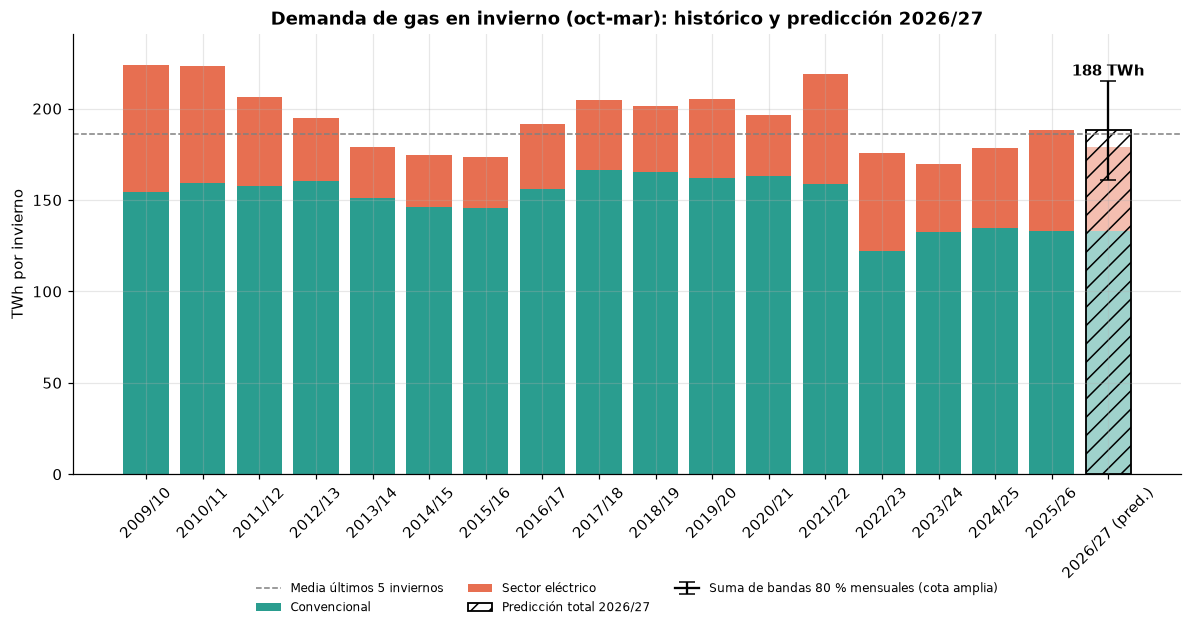

,Total,Convencional,Sector eléctrico,% eléctrico
2019/20,205.40,161.80,43.60,21.20
2020/21,196.30,163.30,33.00,16.80
2021/22,219.20,158.60,60.60,27.70
2022/23,175.90,122.20,53.70,30.50
2023/24,169.90,132.70,37.20,21.90
2024/25,178.40,134.70,43.70,24.50
2025/26,188.10,133.30,54.80,29.10
2026/27 (pred.),188.10,133.30,45.60,24.30


In [29]:
# Inviernos históricos (octubre del año t a marzo del año t+1) en TWh
hist = monthly_twh.copy()
hist["winter"] = np.where(hist.index.month >= 10, hist.index.year, hist.index.year - 1)
hist = hist[hist.index.month.isin([10, 11, 12, 1, 2, 3])]
winters = hist.groupby("winter")[SERIES].sum()
winters = winters[hist.groupby("winter").size() == 6]          # solo inviernos completos
winters.index = [f"{y}/{str(y + 1)[2:]}" for y in winters.index]
winters.loc["2026/27 (pred.)"] = winter_tbl.loc["Invierno oct-mar"]

fig, ax = plt.subplots(figsize=(13, 5.2))
x = np.arange(len(winters))
alpha = [1] * (len(x) - 1) + [0.45]          # la barra prevista, más clara
for i in x:
    ax.bar(i, winters["Convencional"].iloc[i], color=COLORS["Convencional"], alpha=alpha[i], label="Convencional" if i == 0 else None)
    ax.bar(i, winters["Sector eléctrico"].iloc[i], bottom=winters["Convencional"].iloc[i], color=COLORS["Sector eléctrico"],
           alpha=alpha[i], label="Sector eléctrico" if i == 0 else None)
w_hat = winters["Total"].iloc[-1]
tot = winter[winter.unique_id == "Total"][["lo80", "hi80"]].sum()
ax.bar(x[-1], w_hat, fill=False, edgecolor="black", hatch="//", lw=1.2, label="Predicción total 2026/27")
ax.errorbar(x[-1], w_hat, yerr=[[w_hat - tot["lo80"]], [tot["hi80"] - w_hat]], color="black", capsize=5,
            label="Suma de bandas 80 % mensuales (cota amplia)")
ax.axhline(winters["Total"].iloc[-6:-1].mean(), color="grey", ls="--", lw=1, label="Media últimos 5 inviernos")
ax.annotate(f"{w_hat:.0f} TWh", (x[-1], tot["hi80"] + 3), ha="center", fontweight="bold")
ax.set_xticks(x, winters.index, rotation=45)
ax.set_ylim(0, tot["hi80"] * 1.12)
ax.set(title="Demanda de gas en invierno (oct-mar): histórico y predicción 2026/27", ylabel="TWh por invierno")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.show()

comp = winters.copy()
comp["% eléctrico"] = 100 * comp["Sector eléctrico"] / comp["Total"]
comp.tail(8).round(1)

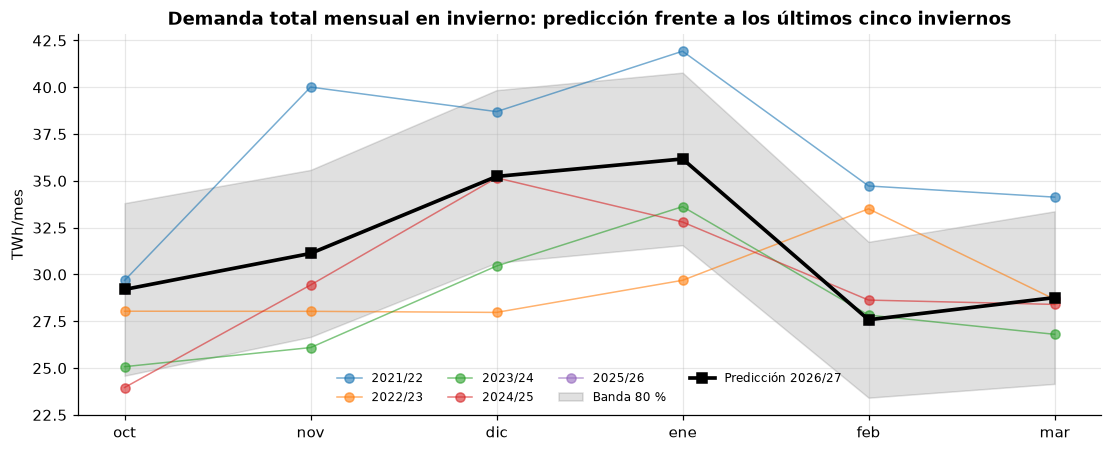

In [30]:
# Perfil mensual del invierno previsto frente a los cinco anteriores
fig, ax = plt.subplots(figsize=(12, 4.5))
order = [10, 11, 12, 1, 2, 3]
labels = ["oct", "nov", "dic", "ene", "feb", "mar"]
for y0 in range(2021, 2026):
    seg = monthly_twh.loc[f"{y0}-10-01":f"{y0 + 1}-03-01", "Total"]
    ax.plot(labels, seg.values, marker="o", lw=1, alpha=0.6, label=f"{y0}/{str(y0 + 1)[2:]}")
wt = winter[winter.unique_id == "Total"]
ax.fill_between(labels, wt["lo80"], wt["hi80"], color="black", alpha=0.12, label="Banda 80 %")
ax.plot(labels, wt["y_hat"], marker="s", color="black", lw=2.4, label="Predicción 2026/27")
ax.set(title="Demanda total mensual en invierno: predicción frente a los últimos cinco inviernos", ylabel="TWh/mes")
ax.legend(ncol=4, fontsize=8)
plt.show()

**Comparación con los inviernos anteriores.**
- Los 188 TWh previstos son la **misma cifra que el invierno 2025/26** (el seasonal naïve lo copia), **+1 %** sobre la media de los últimos cinco inviernos (186 TWh) y **+5 %** sobre 2024/25 (178 TWh).
- Siguen **por debajo de los inviernos previos a 2022** (196-219 TWh): la demanda convencional se ha quedado en un escalón más bajo, de ~133 TWh por invierno frente a ~160 antes de la crisis.
- El peso del sector eléctrico en invierno ha pasado de ~17-21 % (2019/20 y 2020/21) a **~29 % en 2025/26**. Cada invierno depende más del gas para generar electricidad.
- La barra de error suma las bandas mensuales del 80 %, así que es una **cota amplia** (supone que todos los meses se desvían en el mismo sentido). Va de 161 a 215 TWh.

### F.2 · Contraste con los avances mensuales de Enagás (abril-agosto de 2026)

La CNMC publica con retraso, pero Enagás GTS publica cada mes un **«Progreso mensual de la demanda»**. Tomamos la tabla *Demanda* (página 3) de los informes de marzo a septiembre de 2026. Primero comprobamos que las dos fuentes miden lo mismo en el mes que comparten, marzo de 2026:

In [31]:
# Avances mensuales de Enagás GTS («Progreso mensual de la demanda»), cifras de la tabla «Demanda»
# de la página 3 de cada informe (TWh, redondeadas a un decimal). Transcritas de los PDF publicados en:
ENAGAS_URL = ("https://www.enagas.es/content/dam/enagas/es/ficheros/gestion-tecnica-sistema/energy-data/"
              "publicaciones/demanda-de-gas/demanda-mensual/Progreso_{mes}26.pdf")
enagas = pd.DataFrame({
    "ds": pd.to_datetime(["2026-03-01", "2026-04-01", "2026-05-01", "2026-06-01", "2026-07-01", "2026-08-01", "2026-09-01"]),
    "informe": ["marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre"],
    "Convencional": [20.9, 16.4, 17.0, 15.3, 15.3, 13.1, 14.6],
    "Sector eléctrico": [7.9, 6.6, 7.2, 8.6, 12.2, 12.0, 11.2],
    "Total": [28.8, 23.1, 24.2, 23.8, 27.5, 25.1, 25.8],
}).set_index("ds")

# Comprobación de consistencia en el mes que se solapa con la CNMC (marzo 2026)
chk = pd.DataFrame({"CNMC": monthly_twh.loc["2026-03-01", SERIES], "Enagás (avance)": enagas.loc["2026-03-01", SERIES]})
chk["Diferencia"] = chk["CNMC"] - chk["Enagás (avance)"]
print("Marzo 2026 — misma cifra en ambas fuentes (TWh):")
chk.round(2)

Marzo 2026 — misma cifra en ambas fuentes (TWh):


,CNMC,Enagás (avance),Diferencia
Total,28.77,28.80,-0.03
Convencional,20.91,20.90,0.01
Sector eléctrico,7.85,7.90,-0.05


Las diferencias son de **±0,05 TWh**, que es el redondeo a un decimal de Enagás. **Las dos fuentes son comparables** y podemos contrastar con el avance la predicción hecha solo con datos de la CNMC.

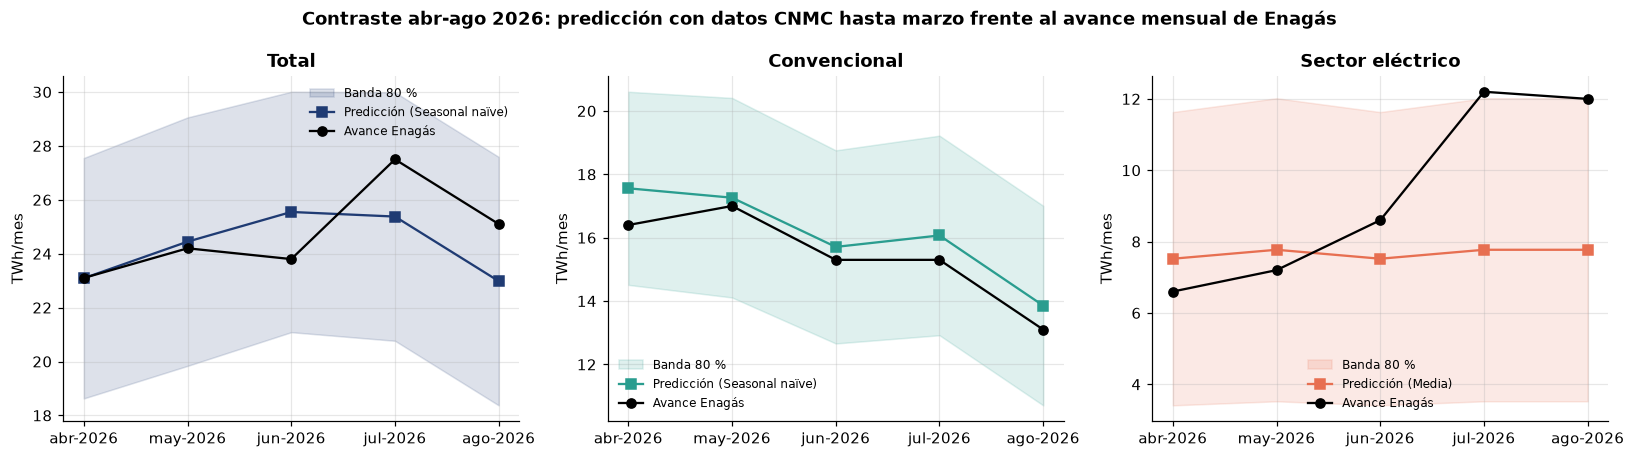

Serie,Total,Convencional,Sector eléctrico
abr-2026,-0.00,7.10,13.90
may-2026,1.00,1.50,7.90
jun-2026,7.30,2.70,-12.60
jul-2026,-7.70,5.00,-36.30
ago-2026,-8.40,5.80,-35.20


,Pred. abr-ago,Enagás abr-ago,MAE (TWh/mes),Meses en banda 80 %,Sesgo acumulado (TWh),Sesgo %
Serie,,,,,,
Total,121.44,123.70,1.25,5,-2.26,-1.82
Convencional,80.46,77.10,0.67,5,3.36,4.35
Sector eléctrico,38.35,46.60,2.25,4,-8.25,-17.70


In [32]:
pred = fc_best.pivot(index="ds", columns="unique_id", values="y_hat")[SERIES]
lo, hi = (fc_best.pivot(index="ds", columns="unique_id", values=c)[SERIES] for c in ("lo80", "hi80"))
months = pd.date_range("2026-04-01", "2026-08-01", freq="MS")

rows = []
for s in SERIES:
    for d in months:
        real, p = enagas.loc[d, s], pred.loc[d, s]
        rows.append({"Serie": s, "Mes": mes(d), "Predicción": p, "Enagás": real,
                     "Error (pred − real)": p - real, "Error %": 100 * (p - real) / real,
                     "Dentro banda 80 %": lo.loc[d, s] <= real <= hi.loc[d, s]})
cmp = pd.DataFrame(rows)

agg = cmp.groupby("Serie", sort=False).agg(**{"Pred. abr-ago": ("Predicción", "sum"), "Enagás abr-ago": ("Enagás", "sum"),
                                              "MAE (TWh/mes)": ("Error (pred − real)", lambda e: e.abs().mean()),
                                              "Meses en banda 80 %": ("Dentro banda 80 %", "sum")})
agg["Sesgo acumulado (TWh)"] = agg["Pred. abr-ago"] - agg["Enagás abr-ago"]
agg["Sesgo %"] = 100 * agg["Sesgo acumulado (TWh)"] / agg["Enagás abr-ago"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, s in zip(axes, SERIES):
    c = cmp[cmp.Serie == s]
    ax.fill_between(c["Mes"], lo.loc[months, s], hi.loc[months, s], color=COLORS[s], alpha=0.15, label="Banda 80 %")
    ax.plot(c["Mes"], c["Predicción"], marker="s", color=COLORS[s], label=f"Predicción ({LABELS[best_model[s]]})")
    ax.plot(c["Mes"], c["Enagás"], marker="o", color="black", label="Avance Enagás")
    ax.set(title=s, ylabel="TWh/mes")
    ax.legend(fontsize=8)
fig.suptitle("Contraste abr-ago 2026: predicción con datos CNMC hasta marzo frente al avance mensual de Enagás", fontweight="bold")
plt.tight_layout()
plt.show()

display(cmp.pivot(index="Mes", columns="Serie", values="Error %")[SERIES].loc[months.map(mes)].round(1))
agg.round(2)

**Lectura del contraste (abril-agosto de 2026).**
- **Total: buen resultado.** El seasonal naïve predice 121,4 TWh frente a los 123,7 reales, un **−1,8 %**, con un error medio de 1,25 TWh/mes y **los cinco meses dentro de la banda del 80 %**. Pero acierta por compensación: julio y agosto se quedan cortos (−8 %) y abril-junio aciertan o se pasan.
- **Convencional: sobreestima un +4,4 %.** La demanda real está un 2-6 % por debajo del año anterior en todos los meses (y un −9,7 % en septiembre). Es la reacción esperable a un TTF de ~80 €/MWh, **una versión suave de 2022**.
- **Sector eléctrico: infraestima un −17,7 %, y en julio-agosto un −36 %.** El gas para generación crece más de un **31 % interanual** en julio, agosto y septiembre (abril: hidráulica −30 % y eólica −14 %). La media histórica no puede captar esa subida.
- **En conjunto, los dos errores se compensan:** menos convencional y más eléctrica. Esa compensación no está garantizada en invierno, cuando la convencional pesa mucho más.

In [33]:
# Alternativa: ¿qué habría dado el seasonal naïve en el sector eléctrico (y la media en las demás)?
months_obs = pd.date_range("2026-04-01", "2026-09-01", freq="MS")
alt = to_twh(fc_full, MODEL_NAMES).set_index(["unique_id", "ds"])
rows = []
for s in SERIES:
    real = enagas.loc[months_obs, s]
    for m in MODEL_NAMES:
        p = alt.loc[s].loc[months_obs, m]
        rows.append({"Serie": s, "Modelo": LABELS[m], "Pred. abr-sep (TWh)": p.sum(), "Enagás abr-sep (TWh)": real.sum(),
                     "MAE (TWh/mes)": (p - real).abs().mean(), "Sesgo %": 100 * (p.sum() / real.sum() - 1)})
pd.DataFrame(rows).set_index(["Serie", "Modelo"]).round(2)

Pred. abr-sep (TWh)  Enagás abr-sep (TWh)  \
Serie            Modelo                                                      
Total            Media                        177.01                149.50   
                 Naïve                        169.81                149.50   
                 Seasonal naïve               146.04                149.50   
                 Drift                        168.73                149.50   
Convencional     Media                        131.14                 91.70   
                 Naïve                        123.45                 91.70   
                 Seasonal naïve                96.59                 91.70   
                 Drift                        122.87                 91.70   
Sector eléctrico Media                         45.87                 57.80   
                 Naïve                         46.35                 57.80   
                 Seasonal naïve                49.45                 57.80   
                 Drift                         45.86                 57.80   

                                 MAE (TWh/mes)  Sesgo %  
Serie            Modelo                                  
Total            Media                    4.58    18.40  
                 Naïve                    3.38    13.58  
                 Seasonal naïve           1.24    -2.31  
                 Drift                    3.21    12.87  
Convencional     Media                    6.57    43.01  
                 Naïve                    5.29    34.63  
                 Seasonal naïve           0.82     5.34  
                 Drift                    5.19    33.99  
Sector eléctrico Media                    2.48   -20.64  
                 Naïve                    2.46   -19.80  
                 Seasonal naïve           1.81   -14.45  
                 Drift                    2.52   -20.65

**¿Habría ido mejor otro método en el sector eléctrico?** Con abril-septiembre de 2026, el seasonal naïve del sector eléctrico tiene un sesgo del −14 %, frente al −21 % de la media, y en el total y en la convencional sigue siendo con diferencia el mejor método. **El ganador del bloque D en el sector eléctrico no se mantiene fuera de muestra**: con 12 meses de prueba y una serie con cambios de régimen, la elección del mejor método es frágil. Es otro motivo para usar el **seasonal naïve sobre el total** como cifra principal.

In [34]:
# Septiembre 2026 ya publicado por Enagás: último dato antes del invierno
sep = pd.DataFrame({"Predicción": pred.loc["2026-09-01"], "Enagás": enagas.loc["2026-09-01", SERIES]})
sep["Error %"] = 100 * (sep["Predicción"] - sep["Enagás"]) / sep["Enagás"]
sep.round(2)

,Predicción,Enagás,Error %
Total,24.60,25.80,-4.66
Convencional,16.14,14.60,10.54
Sector eléctrico,7.52,11.20,-32.86


**Septiembre de 2026**, el último dato antes del invierno, confirma las mismas tendencias: la convencional está un 10 % por debajo de lo previsto y el eléctrico un 33 % por encima. El total se queda corto en un 4,7 %.

### F.3 · Escenario corregido con la información de abril-septiembre

Un ajuste sencillo, sin pretensiones de modelo: si en invierno se mantuviera la desviación observada entre abril y septiembre en cada componente, ¿cuánto gas haría falta?

In [35]:
# Ajuste ingenuo por sesgo observado: si el sesgo de abr-sep se mantuviese en invierno
ratio = enagas.loc[months_obs, SERIES].sum() / pred.loc[months_obs, SERIES].sum()
adj = winter_tbl.loc["Invierno oct-mar", SERIES]
scen = pd.DataFrame({
    "Base (benchmark)": adj,
    "Ratio real/pred. abr-sep": ratio,
    "Escenario corregido": adj * ratio,
})
# Coherencia: total corregido = suma de componentes corregidos
scen.loc["Total (suma comp.)"] = [adj[["Convencional", "Sector eléctrico"]].sum(), np.nan,
                                  scen.loc[["Convencional", "Sector eléctrico"], "Escenario corregido"].sum()]
scen.round(2)

,Base (benchmark),Ratio real/pred. abr-sep,Escenario corregido
Total,188.08,1.02,192.53
Convencional,133.32,0.95,126.56
Sector eléctrico,45.62,1.26,57.48
Total (suma comp.),178.94,NaN,184.04


**Lectura.** Las dos formas de corregir dan **entre 184 TWh** (corrigiendo cada componente por separado: convencional −5 %, eléctrico +26 %) **y 193 TWh** (corrigiendo el total). El intervalo **184-193 TWh** es el rango central razonable para el invierno. El escenario por componentes es más bajo porque en invierno pesa más la convencional, que es la que está cayendo.

### F.4 · Tres recomendaciones para el Ministerio

**1. Asegurar suministro para unos 190 TWh entre octubre y marzo, con el refuerzo de GNL concentrado en diciembre y enero.**
La cifra central es de 188 TWh y el rango, de 184-193 TWh. Diciembre y enero suman ~71 TWh, a una media de ~1,15 TWh/día, y en días fríos laborables la demanda puede superar los 1.600-1.800 GWh/día (máximo de la serie: 1.886 GWh/día). Con los almacenamientos al 73 % y el mercado de GNL tensionado por Ormuz, conviene **contratar ahora los cargamentos de diciembre y enero** y reservar la extracción de almacenamientos para cubrir las puntas, no el consumo de base. Subestimar cuesta más que sobreestimar: en el año de prueba, el método de referencia se quedó corto en 20 TWh.

**2. Crear un seguimiento mensual del gas para generación eléctrica, coordinado con REE.**
Es la componente que más se desvía (+26 % sobre lo previsto entre abril y septiembre; +31-33 % interanual en julio-septiembre) y la que define el riesgo al alza. Proponemos **recalcular la predicción cada mes con el avance de Enagás**, sin esperar al dato trimestral de la CNMC, y cruzarla con las reservas hidráulicas, la previsión eólica, la disponibilidad nuclear y el modo de operación reforzado de REE. Si el eléctrico mantiene el ritmo del verano (+30 %), el invierno se acercaría a ~200 TWh.

**3. Preparar, pero no activar todavía, un plan de reducción de demanda con disparadores objetivos.**
La demanda convencional ya se está ajustando sola por precio (−4 % en lo que va de año y −10 % en septiembre), así que imponer medidas hoy tendría un coste económico y poco margen de ahorro adicional. Proponemos dejar listo un paquete en la línea del de 2022 (Real Decreto-ley 14/2022: termostatos, iluminación, interrumpibilidad industrial voluntaria) que se active si se cumple alguna de estas condiciones: (a) la demanda mensual supera el **límite superior de la banda del 80 %** dos meses seguidos; (b) llega una ola de frío prolongada en diciembre-enero, o (c) el llenado de los almacenamientos cae por debajo de la senda de seguridad acordada con Enagás.

### F.5 · Limitaciones

- **Métodos de referencia, no modelos de producción.** El seasonal naïve supone que el invierno 2026/27 repetirá el 2025/26, **también su meteorología**. Un invierno frío podría añadir un 5-10 % a la convencional. La temperatura entrará en la fase X9.
- **Un cambio estructural que la historia no recoge.** El cierre de Ormuz y un TTF de 80 €/MWh no tienen precedente en la muestra, salvo el paralelismo parcial de 2022. Los métodos univariantes no "saben" que los precios han subido.
- **Los intervalos son optimistas.** Los residuos están autocorrelacionados (Ljung-Box p < 0,001) y la suma de bandas mensuales no es una banda del invierno completo.
- **Componentes incoherentes.** Usar el método ganador en cada serie hace que componentes y total no cuadren (9 TWh de diferencia). Una reconciliación jerárquica lo resolvería.
- **Datos con retraso y avances provisionales.** La CNMC llega hasta marzo de 2026. Los datos de Enagás son provisionales, están redondeados a 0,1 TWh y se han transcrito manualmente de sus PDF.
- **El dato mensual oculta las puntas diarias.** La capacidad de emisión del sistema (TWh/día) es una restricción distinta del volumen mensual y requiere un análisis diario específico.

**Próximos pasos de la práctica transversal:** ETS (X6) y ARIMA (X7-X8) para aprovechar la persistencia que dejan los residuos, y la temperatura como variable externa (X9).